# Final report extrapolations 2 — two moving targets: averaging or choosing?

**Question.** When a fish follows two targets that move side by side, does it swim between them (it **averages** their
directions) or follow one of them (it **chooses**)? Zebrafish of 24–26 dpf following two virtual conspecifics that move
back and forth in parallel switch from the first to the second as the two move apart (Sridhar et al. 2021, PNAS 118,
e2102157118, Fig. 3C; flies and locusts do the same, at angular separations of about 110° and 90°). A model that combined
two groups as fish do should show the same switch: a **bifurcation** in where the fish sits as the separation grows.

The recorded programme never shows two groups at once, so the trained models' behaviour here is fixed by the rule that
turns two groups into the network's input. Five rules on the same trained weights, no retraining:

- **effects** — each group alone through the whole network against a no-dots baseline; the effects are added.
- **add** / **avg** — one input row with the groups' stimulus columns summed / averaged.
- **nearest** — the nearest group only.
- **heading κ** (new) — as *effects*, but the group effects are combined with weights summing to one,
  w_i = softmax_i(κ cos φ_i), φ_i the group's bearing from the fish's heading. Groups nearly straight ahead weigh about
  equally (the effects are averaged); of two groups far apart, the one more ahead dominates and turns the fish further
  toward it — the positive feedback behind a switch. κ = 0 (the plain average of the effects, a control), 0.25, 0.5, 1, 2, 4. With one group w = 1: exactly the standard model
  (checked bout for bout).

## Contents

1. [Setup](#setup)
2. [The bifurcation curve: identical targets](#symmetric) — 1 v 1 and 4 v 4
   - [The bifurcation map, as in Sridhar et al. Fig. 3C](#map)
   - [The fine map and where each rule splits](#fine)
   - [Out to 100 mm: a dish of twice the radius](#big)
   - [Equidistant start: the onset anchored on the fish](#anch)
   - [The maps over the whole block (0–60 s)](#full)
   - [Unequal pairs out to 100 mm, equidistant start](#uneq)
3. [Where the fish sits: distributions](#dist)
4. [Unequal targets](#asym) — 1 v 4 and 2 v 8
5. [The onset window](#onset)
6. [Numbers](#numbers)
7. [What it shows](#reading)
8. [A video of the experiment](#video)
   - [The same with an equidistant start](#video-anch)
9. [The report maps](#report-maps)
   - [The same maps with every bout](#report-maps-all)
   - [The same maps with the paper's rule: bouts behind the pair](#report-maps-behind)

<a id="setup"></a>
## 1. Setup

**Scene** (`scripts/two_targets.py`). Two moving dot groups A and B. Their centroids move back and forth on two parallel
tracks through the dish centre, ±20 mm along the track, in step, at 2 mm/s (the trained moving centroids move at
1.1–3.5 mm/s, 8 to 1 dots); the tracks are L apart, L = 0, 5, 10, 15, 20, 30, 40 mm. The track direction is random per
block, A alternates sides between blocks. A simulated fish swims a 100 s lead-in pause, then 10 blocks of 60 s with the
targets, each followed by a 50 s pause, so the block clock starts at each onset as in training. 15 simulated fish per
condition (3 per fold model) = 150 trials; every fish has the same start, latent, random stream and tracks in every
condition (paired by fish).

**Pairs.** 1 v 1 and 4 v 4 (identical targets: a clean bifurcation needs symmetry); 1 v 4 and 2 v 8 (unequal, 4:1).
**References** on the same tracks: only A shown, only B shown (the fish committed to one target).

**Readout.** A bout is *following* when the fish is behind the pair along the direction the targets move (within 40 mm)
and within L/2 + 15 mm of the midline; its lateral offset from the midline is read in mm. A fish following ONE target
wanders 6–7 mm to either side of it, so a raw offset mixes where the fish sits with how loosely it follows. Every rule is
therefore read against two references on the same tracks, which carry that scatter: the **midline follower** (one target
on the midline, the L = 0 run with only A shown, read at separation L) = **averaging**, and the fish shown **only A** =
**choosing**. Readouts per trial, then mean over fish with a 95 % bootstrap CI over fish:
- **share near the midline**, the share of following bouts within L/4 of the midline: the midline follower's value rises
  with L, the committed fish's stays low; a switch shows as a rule leaving the first curve for the second;
- **commitment index**, from the mean |offset|: 0 = the midline follower, 1 = the fish shown only A;
- for unequal pairs, the mean signed offset (toward A, the smaller group) and the share of following bouts closer to the
  larger group.

Below about 15 mm the two references are not distinguishable (the separation is within the fish's own scatter), so only
L ≥ 15–20 mm is informative. Main window 20–60 s (steady following, after the onset response, where F's correction is
off); 0–20 s as a secondary window.

Models: M6 (26e | 30d) and F (14f | 32b), seed 0 | seed 101, never pooled.

In [ ]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "../scripts")
import two_targets as TT
S = TT.summary(window="steady")
S1 = TT.summary(window="onset")
RC = {"effects": "#1f77b4", "add": "#ff7f0e", "avg": "#2ca02c", "nearest": "#d62728",
      "heading0": "#efe6f4", "heading0.25": "#e4d3ec", "heading0.5": "#d3b7e2", "heading1": "#b48ad0", "heading2": "#8c5bb5",
      "heading4": "#4b2a6b", "ref-A": "#000000", "ref-B": "#555555", "ref-mid": "#8a8a8a"}
UNITS = [("26e", "M6 s0"), ("30d", "M6 s101"), ("14f", "F s0"), ("32b", "F s101")]
print(len(S), "conditions;", "trials per condition:", int(S.n_trials.min()), "-", int(S.n_trials.max()),
      "; following bouts per trial (steady):", round(S.follow_bouts.mean(), 1))

1384 conditions; trials per condition: 148 - 150 ; following bouts per trial (steady): 15.0


<a id="symmetric"></a>
## 2. The bifurcation curve: identical targets

Top: the share of following bouts near the midline (within L/4) against the separation L, 20–60 s. Grey dashed: the
midline follower (averaging); black dashed: the fish shown only A (choosing). Bottom: the commitment index (0 =
averaging, 1 = choosing). **What a fish would show** (Sridhar et al.): on the averaging curve at small L, leaving it for the
choosing curve beyond a critical separation.

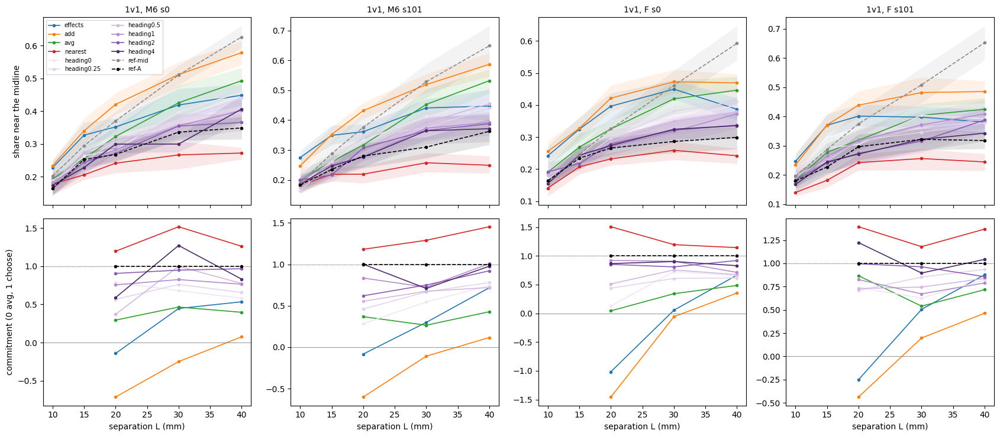

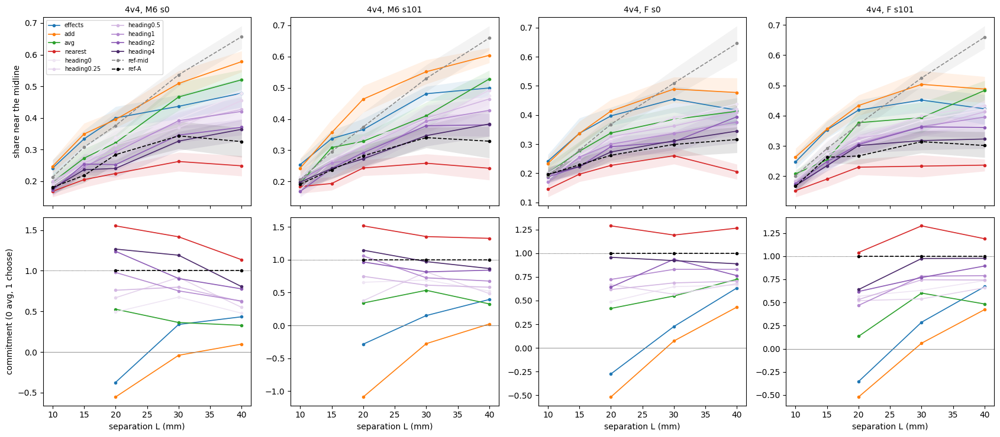

In [ ]:
def curve(ax, S, tag, pair, col="middle", conds=TT.CONDS, refs=("ref-mid", "ref-A"), Lmin=10):
    for c in [c for c in conds if c in TT.RULES] + list(refs):
        d = S[(S.tag == tag) & (S.pair == pair) & (S.cond == c) & (S.L >= Lmin)].sort_values("L")
        if d.empty:
            continue
        ls = "--" if c.startswith("ref") else "-"
        ax.plot(d.L, d[col], ls, color=RC[c], marker="o", ms=3, lw=1.2, label=c)
        if col + "_lo" in d:
            ax.fill_between(d.L, d[col + "_lo"], d[col + "_hi"], color=RC[c], alpha=0.10, lw=0)

for pair in ("1v1", "4v4"):
    fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharex=True)
    for j, (tag, lab) in enumerate(UNITS):
        curve(axes[0, j], S, tag, pair, col="middle")
        curve(axes[1, j], S, tag, pair, col="commit", refs=("ref-A",), Lmin=20)
        axes[0, j].set_title(f"{pair}, {lab}", fontsize=10)
        axes[1, j].axhline(0, color="grey", lw=0.6); axes[1, j].axhline(1, color="k", lw=0.6, ls=":")
        axes[1, j].set_xlabel("separation L (mm)")
    axes[0, 0].set_ylabel("share near the midline"); axes[1, 0].set_ylabel("commitment (0 avg, 1 choose)")
    axes[0, 0].legend(fontsize=7, ncol=2)
    plt.tight_layout()

<a id="map"></a>
## 2b. The bifurcation map, as in Sridhar et al. (2021) Fig. 3C

For each separation L (x axis), the distribution of the following fish's lateral position (y axis, mm from the midline
between the targets; 20–60 s), each column normalised to its own maximum (proportion of maximum), as in their Fig. 3B,C.
Dashed: the two tracks at ±L/2. **Averaging** = one band along y = 0; **choosing** = two branches along the tracks; the
switch shows where the band splits. Last column: the fish shown only A (A's side folded onto +, so the committed
branch). Our separations are 0–40 mm in 7 steps, so the map is coarser along x than theirs.

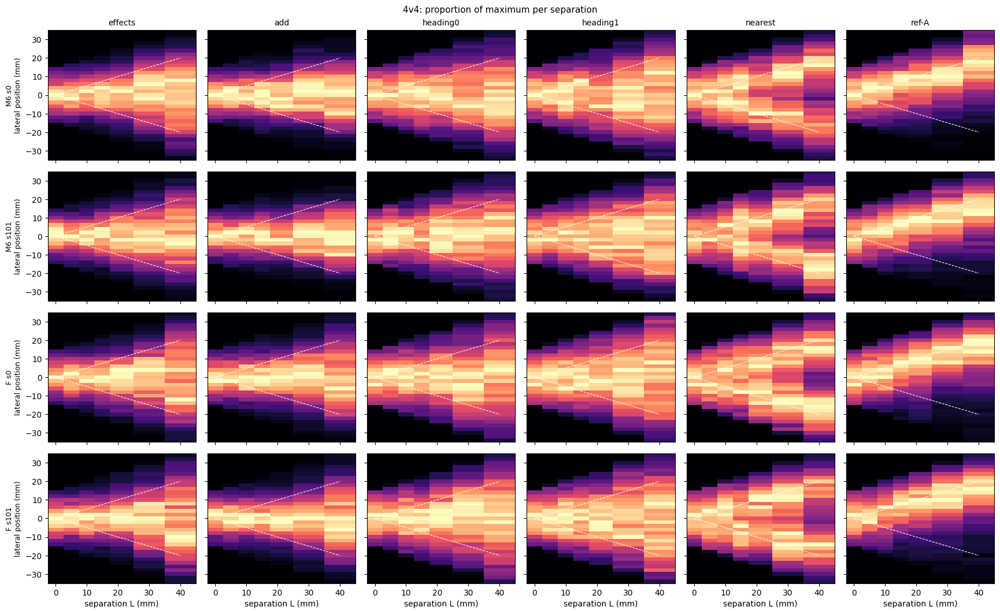

In [ ]:
def bif_map(ax, tag, pair, cond, Ls=TT.SEPS_MM, ymax=35, binw=2.0, arena=1, onset="free", t_min=20,
            cmap="magma", track_col="w", select="following"):
    edges = np.arange(-ymax, ymax + binw, binw)
    xs = np.array(Ls, float)
    xe = np.r_[xs[0] - (xs[1] - xs[0]) / 2, (xs[1:] + xs[:-1]) / 2, xs[-1] + (xs[-1] - xs[-2]) / 2]
    Z = np.zeros((len(edges) - 1, len(xs)))
    for k, L in enumerate(Ls):
        b = TT.load(tag, pair, L, cond, arena, onset)
        if onset == "anchored":                      # the anchoring bout itself sits at lateral 0 by construction
            b = b[b.groupby(["fish", "blk"]).cumcount() > 0]
        w = b[b.t_blk >= t_min]
        f = (TT.following(w, L) if select == "following"
             else w[w.along_mm <= 0] if select == "behind"                # the paper's rule: behind the pair only
             else w)                                                      # 'all': every bout of the window
        h, _ = np.histogram(f.lat_mm, bins=edges)
        Z[:, k] = h / h.max() if h.max() else 0
    mesh = ax.pcolormesh(xe, edges, Z, cmap=cmap, vmin=0, vmax=1, shading="flat")
    ax.plot(xs, xs / 2, "--", color=track_col, lw=0.8); ax.plot(xs, -xs / 2, "--", color=track_col, lw=0.8)
    ax.set_ylim(-ymax, ymax); ax.set_xlim(xe[0], xe[-1])
    return mesh

def map_grid(tags, pair="4v4", conds=("effects", "add", "heading0", "heading1", "nearest", "ref-A")):
    fig, axes = plt.subplots(len(tags), len(conds), figsize=(2.9 * len(conds), 2.7 * len(tags)), sharex=True, sharey=True)
    for i, (tag, lab) in enumerate(tags):
        for j, c in enumerate(conds):
            ax = axes[i, j]
            bif_map(ax, tag, pair, c)
            if i == 0:
                ax.set_title(c, fontsize=10)
            if j == 0:
                ax.set_ylabel(f"{lab}\nlateral position (mm)", fontsize=9)
            if i == len(tags) - 1:
                ax.set_xlabel("separation L (mm)")
    fig.suptitle(f"{pair}: proportion of maximum per separation", fontsize=11)
    plt.tight_layout()

map_grid(UNITS, "4v4")

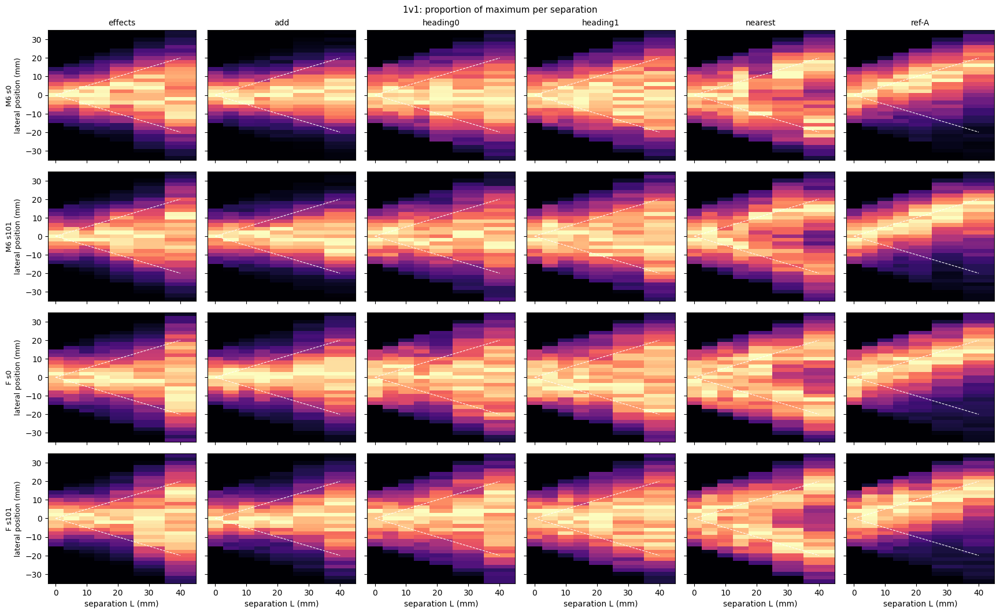

In [ ]:
map_grid(UNITS, "1v1")

<a id="fine"></a>
## 2c. The fine map and where each rule splits

4 v 4 on a fine grid, L = 0–50 mm in 2.5 mm steps, for effects, add, heading κ = 0 and 1, nearest and the one-target
reference. **The split is read from the shape of the lateral distribution**: the following fish's lateral positions
(20–60 s), symmetrised about the midline and smoothed (3 mm kernel); the **dip** = the density at the midline / its
maximum. Dip = 1: the midline is the peak, one band (averaging), however broad or flat-topped; dip < 1: the midline is
a trough between two branches (choosing). **The split = the first separation from which the midline is a clear trough
at every larger L**: the upper 95 % bootstrap bound of the dip (over fish, paired across separations) below 0.9, i.e. the
midline at least 10 % below the branches (a flat-topped band scores 0.95–0.99 from noise alone, so 'below 1' is not
enough). The table gives the split, the median angle the two targets subtend at the following fish there, and the dip at
the largest separation (how deep the trough gets). White dots on the maps: the fitted branch positions ±μ (a symmetric
two-Gaussian fit) from the split on.

A rising μ alone is NOT a split: a band that only broadens raises μ too. The one-target reference (only A shown, its
positions folded to both sides) is the detection floor: the fish's own scatter about the target it follows fills the
midline until the tracks are 35–50 mm apart (4 v 4); **nearest** (two targets, follow the nearer) is resolved earlier,
from 22.5–30 mm, because a fish choosing between two targets is always near one of them.

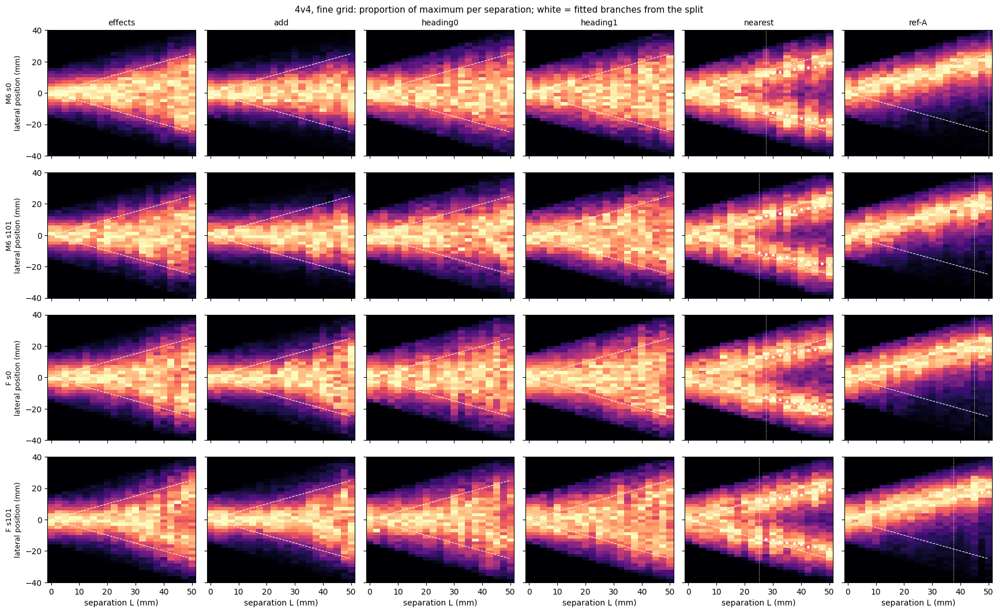

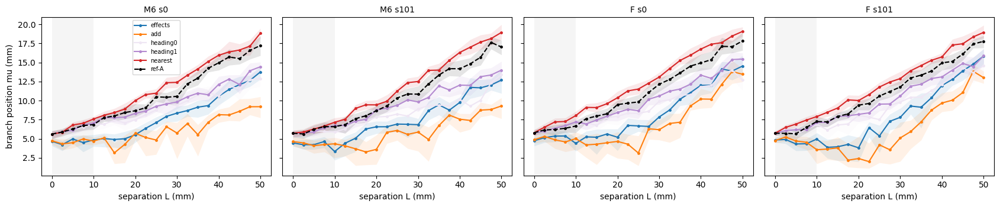

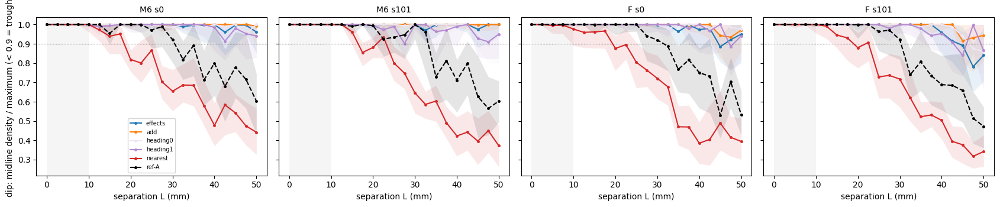

In [ ]:
FT, FS = TT.split_table()
SPL = FS.set_index(["tag", "cond"]).split_L
def fine_map(ax, tag, cond):
    bif_map(ax, tag, "4v4", cond, Ls=TT.FINE_SEPS_MM, ymax=40)
    sl = SPL.get((tag, cond))
    if sl is not None and np.isfinite(sl):
        g = FT[(FT.tag == tag) & (FT.cond == cond) & (FT.L >= sl)]
        ax.plot(g.L, g.mu, "o", color="white", ms=2.5)
        if cond != "ref-A":                                  # only A shown: one branch, on the + side
            ax.plot(g.L, -g.mu, "o", color="white", ms=2.5)
        ax.axvline(sl, color="white", lw=0.8, ls=":")

conds = TT.FINE_CONDS
fig, axes = plt.subplots(len(UNITS), len(conds), figsize=(2.9 * len(conds), 2.7 * len(UNITS)), sharex=True, sharey=True)
for i, (tag, lab) in enumerate(UNITS):
    for j, c in enumerate(conds):
        fine_map(axes[i, j], tag, c)
        if i == 0:
            axes[i, j].set_title(c, fontsize=10)
        if j == 0:
            axes[i, j].set_ylabel(f"{lab}\nlateral position (mm)", fontsize=9)
        if i == len(UNITS) - 1:
            axes[i, j].set_xlabel("separation L (mm)")
fig.suptitle("4v4, fine grid: proportion of maximum per separation; white = fitted branches from the split", fontsize=11)
plt.tight_layout()

for col, ylab, ref in (("mu", "branch position mu (mm)", None),
                       ("dip", "dip: midline density / maximum (< 0.9 = trough)", 0.9)):
    fig, axes = plt.subplots(1, len(UNITS), figsize=(17, 3.6), sharey=True)
    for j, (tag, lab) in enumerate(UNITS):
        ax = axes[j]
        for c in conds:
            g = FT[(FT.tag == tag) & (FT.cond == c)].sort_values("L")
            ax.plot(g.L, g[col], "-o", ms=2.5, color=RC[c], label=c, ls="--" if c.startswith("ref") else "-")
            ax.fill_between(g.L, g[col + "_lo"], g[col + "_hi"], color=RC[c], alpha=0.10, lw=0)
        if ref is not None:
            ax.axhline(ref, color="k", lw=0.7, ls=":")
        ax.axvspan(0, 10, color="grey", alpha=0.08, lw=0)
        ax.set_title(lab, fontsize=10); ax.set_xlabel("separation L (mm)")
    axes[0].set_ylabel(ylab)
    axes[0].legend(fontsize=7)
    plt.tight_layout()

In [ ]:
FSu = FS.assign(unit=lambda d: d.tag.map(dict(UNITS)))
FSu.pivot_table(index="cond", columns="unit", values=["split_L", "angle_at_split", "dip_max_L"]).round(2)

         angle_at_split                       dip_max_L                      split_L                     
unit               F s0 F s101  M6 s0 M6 s101      F s0 F s101 M6 s0 M6 s101    F s0 F s101 M6 s0 M6 s101
cond                                                                                                     
add                 NaN    NaN    NaN     NaN      0.97   0.94  0.99    1.00     NaN    NaN   NaN     NaN
effects             NaN    NaN    NaN     NaN      0.95   0.84  0.96    1.00     NaN    NaN   NaN     NaN
heading0            NaN    NaN    NaN     NaN      0.98   0.86  1.00    0.94     NaN    NaN   NaN     NaN
heading1            NaN    NaN    NaN     NaN      0.94   0.87  0.94    0.95     NaN    NaN   NaN     NaN
nearest           58.35  56.71  61.40   57.08      0.39   0.34  0.44    0.37    27.5   25.0  27.5    25.0
ref-A             83.52  79.55  92.86   89.24      0.53   0.47  0.60    0.60    45.0   37.5  50.0    45.0


<a id="big"></a>
## 2d. Out to 100 mm: a dish of twice the radius

The training dish (radius 49 mm) holds tracks only up to L = 50 mm; Sridhar et al. ran separations to about 100 mm. Here
the dish radius is doubled (98 mm) and L = 0–100 mm in 2.5 mm steps (as the fine map), same tracks (20 mm half-length),
readout and split criterion (the clear midline trough) as in 2c, plus a **blind** fish (no target shown, same tracks and readout box). Two pairs: **1 v 1**, one dot per
target, the closest analogue of the paper's one virtual fish per target, and 4 v 4 as in 2c.

**How the conditions compare with the paper** (Sridhar et al. 2021; the same data re-analysed by Oscar et al. 2023):
- *Targets*: two virtual conspecifics moving in step on parallel straight paths, back and forth, at a fixed lateral
  distance L, re-randomised between trials; here two dot groups on parallel tracks, back and forth, L fixed per run, the
  track axis re-randomised every block. Same.
- *Readout*: only bouts where the fish is behind the targets (the paper: 'only data where the real fish swims behind the
  virtual fish'); lateral position marginalised along the motion direction, each L normalised to its own maximum and
  stacked across L ('proportion of maximum'). Same.
- *Speed*: their leaders move at 4–7 cm/s, about the swimming speed of their 1 cm, 24–26 dpf juveniles; here 2 mm/s,
  inside the trained dot speeds (1.1–3.5 mm/s) and just below our fish's own travel speed (median 2.9 mm/s per fish, 2.0–5.0
  over active bouts). In both the leader moves at about the follower's own speed; the absolute speeds are 20x apart.
- *Fish and scale*: different ages and sizes (our fish's age is not known), dot groups instead of fish images, and our
  fish follow at their own distance behind the targets. Their theory puts the switch at a critical ANGLE subtended by
  the two targets (about 90 deg in their model; flies switch at about 110, locusts at about 90 deg), so a split in mm
  depends on how far behind the targets the fish sits. The table therefore also gives the median angle the two targets
  subtend at the following fish at the split.
- *Timing*: the paper's 90 min session is a series of trials, each starting with a random lateral distance and swim
  direction (L fixed within a trial, not ramped), and the targets U-turn at the arena edge every 6–8 s, which resets
  the chase (the fish turns, re-finds the targets, and left and right are swapped); the columns of their map pool all
  chases at a given L. Here: the trained block structure (60 s with the targets, 50 s pause), L fixed per run, the track
  axis re-drawn every block, a U-turn every 20 s, and the 20–60 s window, as in the rest of this notebook. Whether their
  trials were separated by pauses is not stated in the main text.

What the larger dish changes. Every wall mechanism of the model is relative to the dish radius, so the fish senses the
training dish magnified: its preferred distance from the centre (about 0.45 R) moves from about 22 to about 44 mm, close to
the tracks at the largest separations. That alone could spread the fish to both sides of the midline and look like a
split, so the blind fish is the floor any rule must clear. Range: the model's log-range input saturates at 78 mm, so a
target farther away pulls as one at 78 mm (no range input leaves the trained values; the far target's pull stops fading
beyond 78 mm). Steps, tracks and readout are absolute (mm).

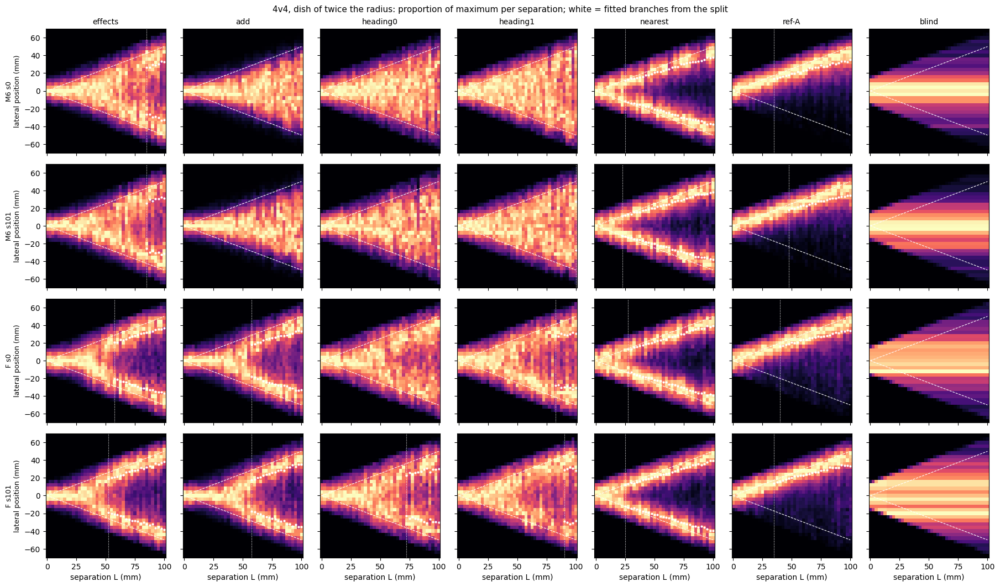

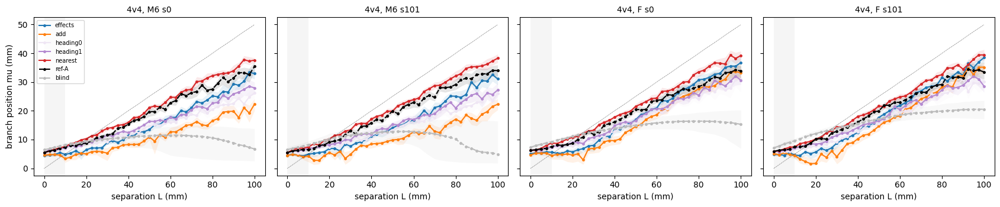

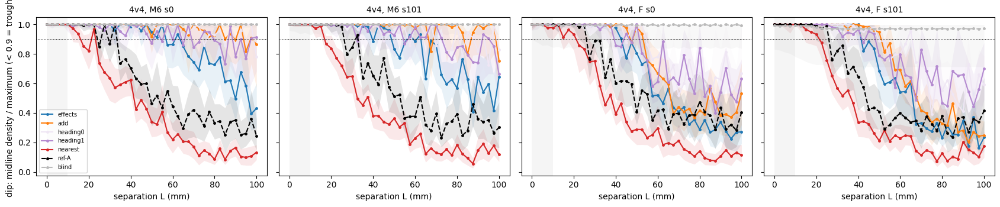

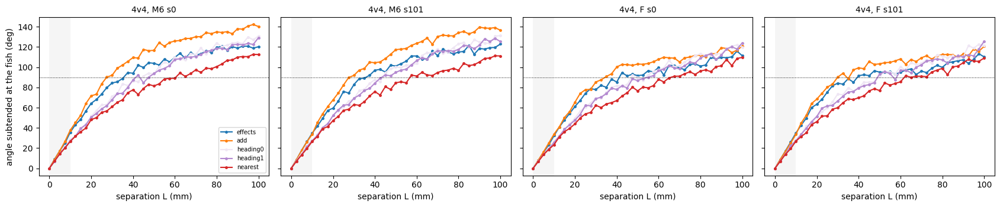

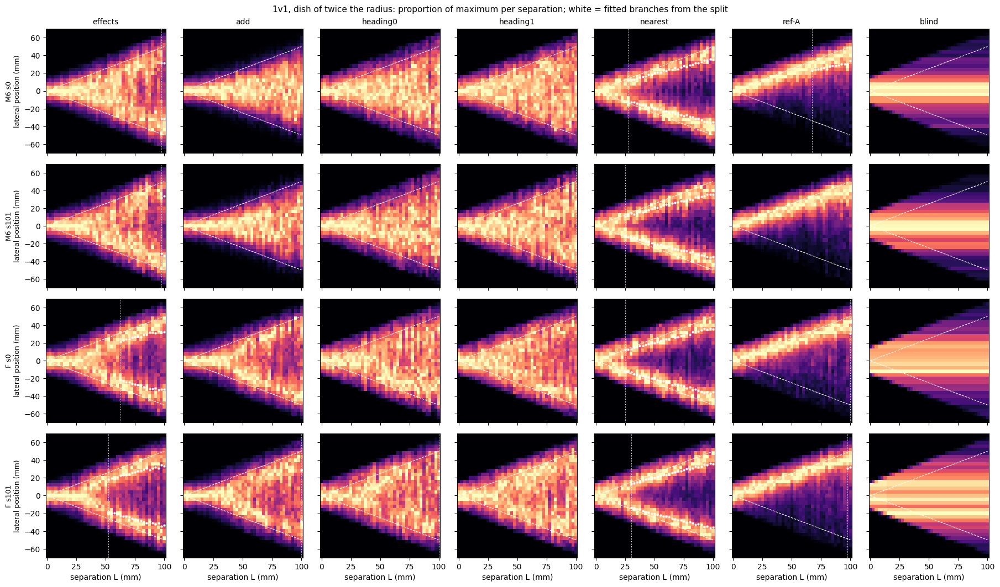

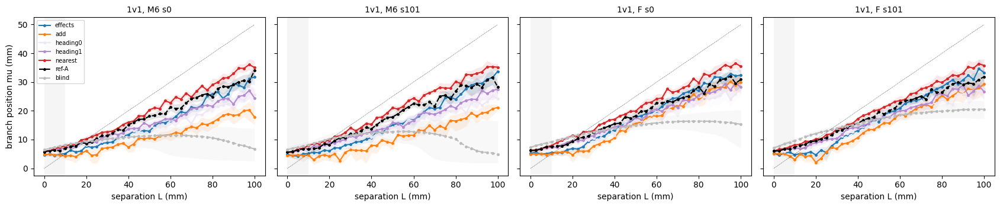

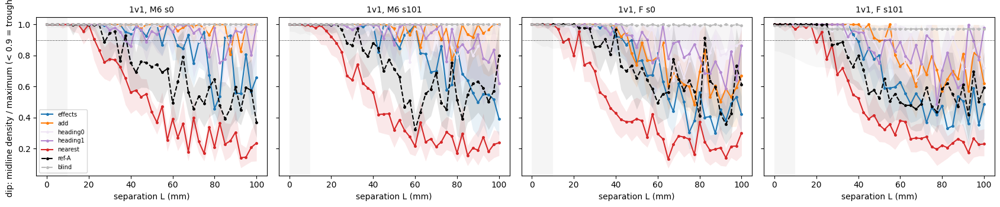

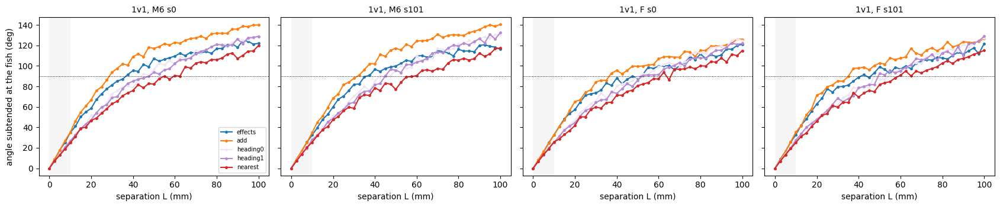

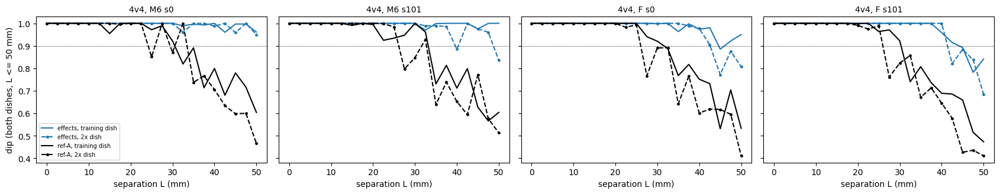

In [ ]:
RCb = dict(RC, blind="#bbbbbb")
conds_b = TT.BIG_CONDS
FTb, FSb = {}, {}
for pair in TT.BIG_PAIRS:
    FTb[pair], FSb[pair] = TT.split_table(pair=pair, arena=TT.ARENA_BIG, seps=TT.BIG_SEPS_MM, conds=conds_b)

def big_maps(pair, FTd=FTb, FSd=FSb, onset="free"):
    T, S_ = FTd[pair], FSd[pair].set_index(["tag", "cond"]).split_L
    fig, axes = plt.subplots(len(UNITS), len(conds_b), figsize=(2.6 * len(conds_b), 2.7 * len(UNITS)), sharex=True,
                             sharey=True)
    for i, (tag, lab) in enumerate(UNITS):
        for j, c in enumerate(conds_b):
            ax = axes[i, j]
            bif_map(ax, tag, pair, c, Ls=TT.BIG_SEPS_MM, ymax=70, binw=4.0, arena=TT.ARENA_BIG, onset=onset)
            sl = S_.get((tag, c))
            if sl is not None and np.isfinite(sl) and c != "blind":
                g = T[(T.tag == tag) & (T.cond == c) & (T.L >= sl)]
                ax.plot(g.L, g.mu, "o", color="white", ms=2)
                if c != "ref-A":                             # only A shown: one branch, on the + side
                    ax.plot(g.L, -g.mu, "o", color="white", ms=2)
                ax.axvline(sl, color="white", lw=0.8, ls=":")
            if i == 0:
                ax.set_title(c, fontsize=10)
            if j == 0:
                ax.set_ylabel(f"{lab}\nlateral position (mm)", fontsize=9)
            if i == len(UNITS) - 1:
                ax.set_xlabel("separation L (mm)")
    fig.suptitle(f"{pair}, dish of twice the radius" + (", onset anchored on the fish (equidistant start)"
                                                        if onset == "anchored" else "")
                 + ": proportion of maximum per separation; white = fitted branches from the split", fontsize=11)
    plt.tight_layout()

def big_curves(pair, FTd=FTb, tag_title=""):
    T = FTd[pair]
    for col, ylab, ref in (("mu", "branch position mu (mm)", None),
                           ("dip", "dip: midline density / maximum (< 0.9 = trough)", 0.9),
                           ("angle", "angle subtended at the fish (deg)", 90)):
        fig, axes = plt.subplots(1, len(UNITS), figsize=(17, 3.6), sharey=True)
        for j, (tag, lab) in enumerate(UNITS):
            ax = axes[j]
            for c in conds_b:
                if col == "angle" and c in ("blind", "ref-A"):
                    continue
                g = T[(T.tag == tag) & (T.cond == c)].sort_values("L")
                ls = "--" if c.startswith("ref") or c == "blind" else "-"
                ax.plot(g.L, g[col], "-o", ms=2.5, color=RCb[c], label=c, ls=ls)
                if col + "_lo" in g:
                    ax.fill_between(g.L, g[col + "_lo"], g[col + "_hi"], color=RCb[c], alpha=0.10, lw=0)
            if col == "mu":
                ax.plot([0, 100], [0, 50], color="k", lw=0.5, ls=":")              # the tracks, L / 2
            if ref is not None:
                ax.axhline(ref, color="k", lw=0.7, ls=":")
            ax.axvspan(0, 10, color="grey", alpha=0.08, lw=0)
            ax.set_title(f"{pair}, {lab}{tag_title}", fontsize=10); ax.set_xlabel("separation L (mm)")
        axes[0].set_ylabel(ylab)
        axes[0].legend(fontsize=7)
        plt.tight_layout()

for pair in TT.BIG_PAIRS:
    big_maps(pair); big_curves(pair)

# the same rule in both dishes (4 v 4, L <= 50 mm): what the magnified dish itself does
fig, axes = plt.subplots(1, len(UNITS), figsize=(17, 3.4), sharey=True)
for j, (tag, lab) in enumerate(UNITS):
    ax = axes[j]
    for c in ("effects", "ref-A"):
        g1 = FT[(FT.tag == tag) & (FT.cond == c)].sort_values("L")
        g2 = FTb["4v4"][(FTb["4v4"].tag == tag) & (FTb["4v4"].cond == c) & (FTb["4v4"].L <= 50)].sort_values("L")
        ax.plot(g1.L, g1.dip, "-", color=RC[c], label=f"{c}, training dish")
        ax.plot(g2.L, g2.dip, "--o", ms=2.5, color=RC[c], label=f"{c}, 2x dish")
    ax.axhline(0.9, color="k", lw=0.7, ls=":")
    ax.set_title(f"4v4, {lab}", fontsize=10); ax.set_xlabel("separation L (mm)")
axes[0].set_ylabel("dip (both dishes, L <= 50 mm)"); axes[0].legend(fontsize=7)
plt.tight_layout()

In [ ]:
FSbu = pd.concat([FSb[p].assign(pair=p) for p in TT.BIG_PAIRS]).assign(unit=lambda d: d.tag.map(dict(UNITS)))
FSbu.pivot_table(index=["pair", "cond"], columns="unit", values=["split_L", "angle_at_split", "dip_max_L"]).round(2)

              angle_at_split                         dip_max_L                      split_L                     
unit                    F s0  F s101   M6 s0 M6 s101      F s0 F s101 M6 s0 M6 s101    F s0 F s101 M6 s0 M6 s101
pair cond                                                                                                       
1v1  add                 NaN  126.90     NaN     NaN      0.67   0.62  1.00    1.00     NaN  100.0   NaN     NaN
     blind               NaN     NaN     NaN     NaN      0.99   0.97  1.00    1.00     NaN    NaN   NaN     NaN
     effects          100.11   96.56  121.28  118.33      0.42   0.49  0.66    0.39    62.5   52.5  97.5    97.5
     heading0            NaN  127.53     NaN     NaN      0.89   0.72  0.96    0.99     NaN  100.0   NaN     NaN
     heading1            NaN     NaN     NaN  132.48      0.87   0.98  1.00    0.62     NaN    NaN   NaN   100.0
     nearest           50.28   59.72   58.30   56.09      0.30   0.23  0.24    0.24    25.0   30

<a id="anch"></a>
## 2e. Equidistant start: the onset anchored on the fish

In 2d the tracks are fixed in the dish, so the fish starts each block wherever the pause left it, often nearer one
group (the nearer group at the first bout is median 35 mm away), and under effects the group it then follows is the
one that was nearer at onset in about two thirds of committed trials (F; M6 0.38–0.73). That decides WHICH branch,
not whether there are two (the readout folds the sides; the blind fish, with the same starts and no pull, keeps one
band). Here the stricter test: every block is anchored on the fish. At its first bout in the block, the pair's midpoint
is put 20 mm ahead of the fish along the track axis, **the fish exactly on the midline, equidistant from A and B**, the
pair starting a leg away from it (axis: from the fish toward the dish centre, turned by a random ±30°, so the tracks stay
inside the dish; the pair starts further ahead, in 5 mm steps, if a track end would lie beyond 0.95 R). Every chase then
starts symmetric, so two branches can only come from the fish breaking the symmetry itself, the bifurcation of the
theory. Everything else as in 2d (2x dish, L = 0–100 mm in 2.5 mm steps, 1 v 1 and 4 v 4, same rules, references,
readout, criterion).

**Result.** The anchoring works: at every block's first bout the fish is exactly on the midline, 20 mm behind the pair's
midpoint (checked). The committed effects trials end on A and on B equally (share on A 0.41–0.57, every unit, both
pairs, L = 60–100 mm), so no side is inherited. Split separations, fixed tracks (2d) → anchored:
- **4 v 4, effects**: F 57.5 → 50 mm (s0), 52.5 → 55 mm (s101), at about 89–90° (95° before); M6 85 → 95 mm and
  85 → 87.5 mm (about 120°, unchanged). Trough depth at 100 mm unchanged (F 0.23–0.26, M6 0.56). **The split survives a
  symmetric start**: the fish breaks the symmetry itself.
- **1 v 1, effects**: F s0 62.5 → 62.5 mm (98°); F s101 52.5 → 97.5 mm (a trough of 0.54–0.67 from 60 mm on, but its
  bootstrap bound reaches 0.9 only at 97.5 mm: the seeds now disagree, so the 1 v 1 split is weaker than the 4 v 4);
  M6 97.5 → 100 and 92.5 mm.
- **add**: F s0 65 mm (4 v 4) only; no split otherwise.
- **heading (any κ)**: no split at all. Its late, shallow troughs with fixed tracks (72.5–100 mm) were INHERITED from the
  onset position: averaging the two effects keeps no symmetric fish from the midline region.
- **nearest**: unchanged (25–32.5 mm, about 55–63°), and the one-target reference as before (4 v 4: 37.5–42.5 mm).

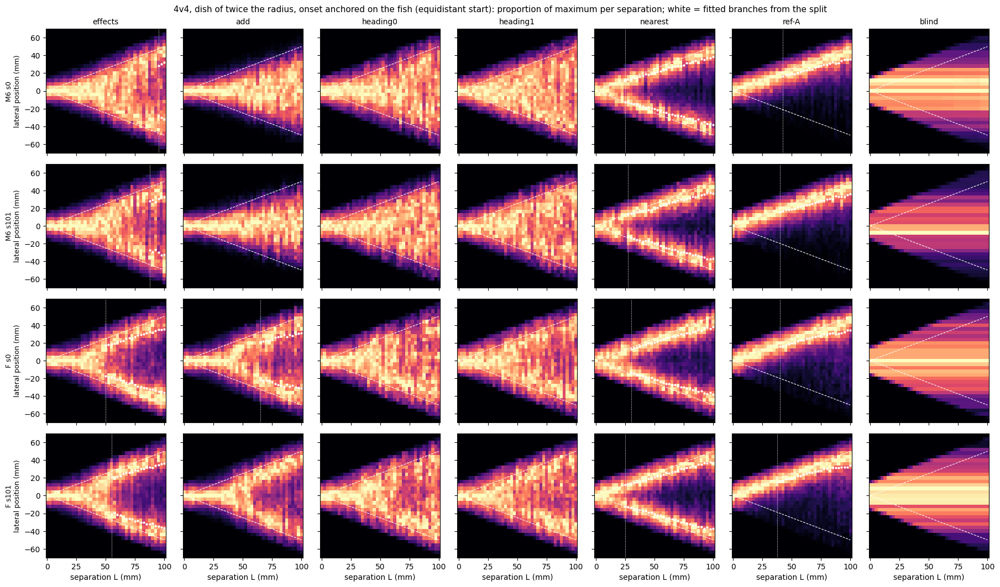

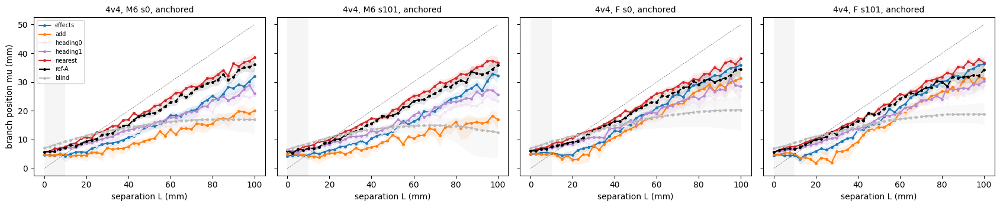

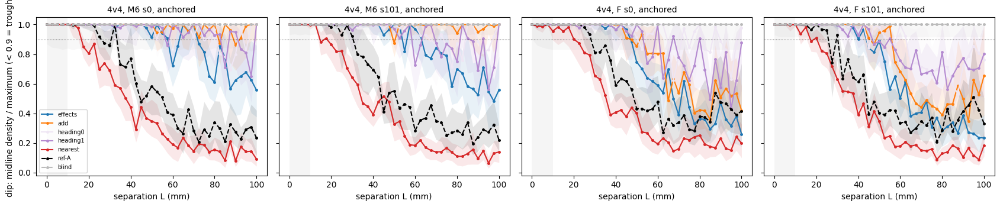

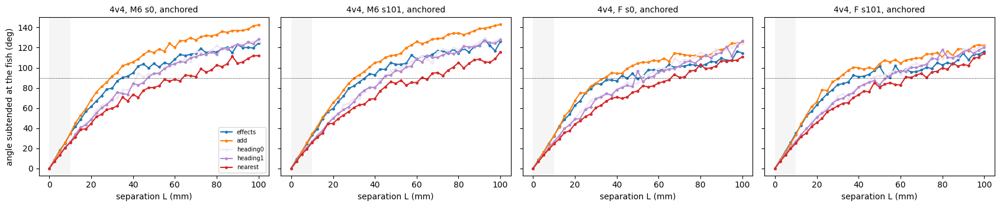

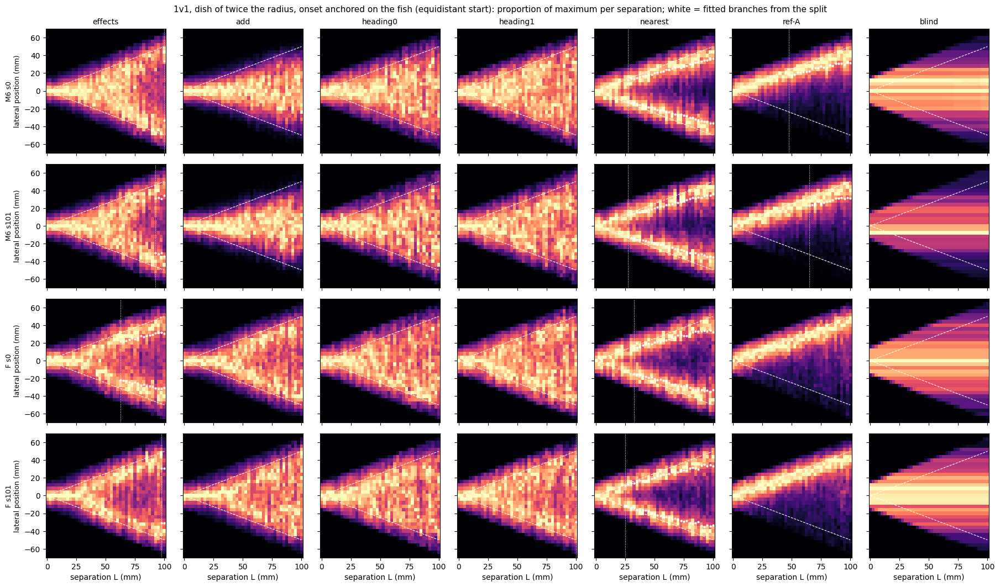

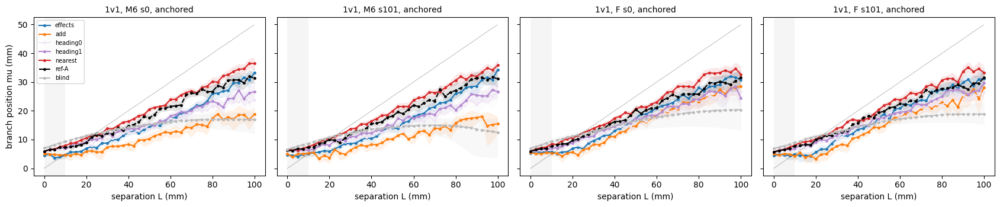

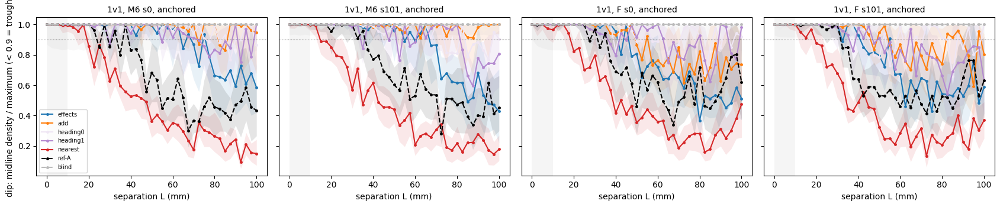

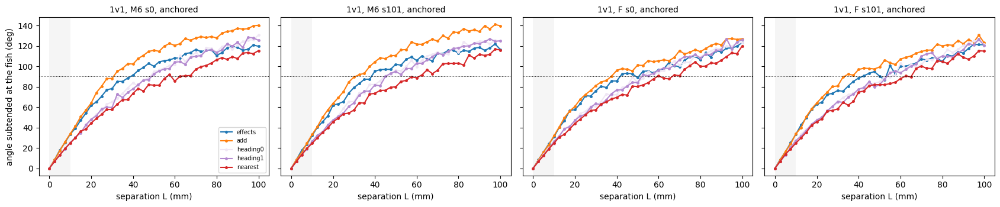

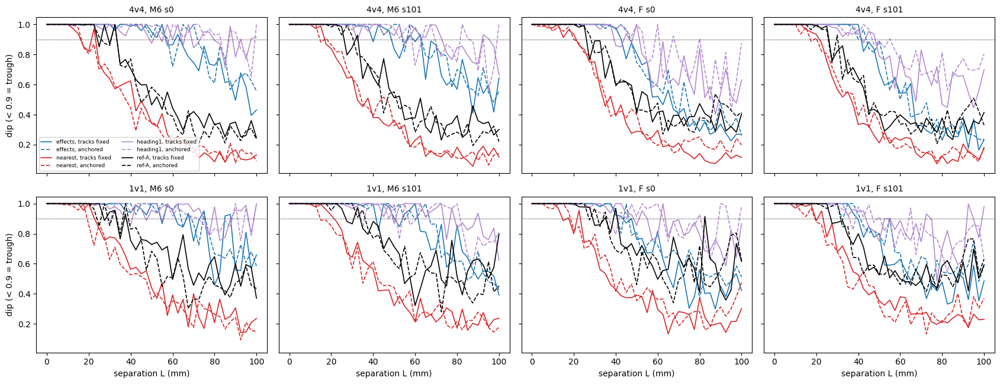

In [ ]:
FTa, FSa = {}, {}
for pair in TT.BIG_PAIRS:
    FTa[pair], FSa[pair] = TT.split_table(pair=pair, arena=TT.ARENA_BIG, seps=TT.BIG_SEPS_MM, conds=conds_b,
                                          onset="anchored")
for pair in TT.BIG_PAIRS:
    big_maps(pair, FTa, FSa, onset="anchored"); big_curves(pair, FTa, tag_title=", anchored")

# fixed tracks (2d) against the anchored onset: the dip of effects and nearest
fig, axes = plt.subplots(2, len(UNITS), figsize=(17, 6.6), sharey=True, sharex=True)
for i, pair in enumerate(TT.BIG_PAIRS):
    for j, (tag, lab) in enumerate(UNITS):
        ax = axes[i, j]
        for c in ("effects", "nearest", "heading1", "ref-A"):
            for D, ls, nm in ((FTb, "-", "tracks fixed"), (FTa, "--", "anchored")):
                g = D[pair][(D[pair].tag == tag) & (D[pair].cond == c)].sort_values("L")
                ax.plot(g.L, g.dip, ls, color=RC[c], lw=1.2, label=f"{c}, {nm}" if (i, j) == (0, 0) else None)
        ax.axhline(0.9, color="k", lw=0.7, ls=":")
        ax.set_title(f"{pair}, {lab}", fontsize=10)
        if i == 1:
            ax.set_xlabel("separation L (mm)")
    axes[i, 0].set_ylabel("dip (< 0.9 = trough)")
axes[0, 0].legend(fontsize=6.5, ncol=2)
plt.tight_layout()

# which group is followed: with a symmetric start there is no nearer group, so the side should be 50:50
rows = []
for pair in TT.BIG_PAIRS:
    for tag, lab in UNITS:
        for L in (60.0, 80.0, 100.0):
            f = TT.following(TT.load(tag, pair, L, "effects", TT.ARENA_BIG, "anchored").query("t_blk >= 20"), L)
            g = f.groupby(["fish", "blk"]).lat_mm.agg(["size", "mean"])
            g = g[(g["size"] >= 5) & (g["mean"].abs() > L / 4)]
            rows.append(dict(pair=pair, unit=lab, L=L, committed=len(g), share_on_A=float((g["mean"] > 0).mean())))
SIDE = pd.DataFrame(rows)

In [ ]:
FSc = pd.concat([FSb[p].assign(pair=p, onset="tracks fixed") for p in TT.BIG_PAIRS]
                + [FSa[p].assign(pair=p, onset="anchored") for p in TT.BIG_PAIRS]).assign(unit=lambda d: d.tag.map(dict(UNITS)))
FSc.pivot_table(index=["pair", "cond"], columns=["onset", "unit"], values="split_L")

onset         anchored                       tracks fixed                     
unit              F s0 F s101  M6 s0 M6 s101         F s0 F s101 M6 s0 M6 s101
pair cond                                                                     
1v1  add           NaN    NaN    NaN     NaN          NaN  100.0   NaN     NaN
     effects      62.5   97.5  100.0    92.5         62.5   52.5  97.5    97.5
     heading0      NaN    NaN    NaN     NaN          NaN  100.0   NaN     NaN
     heading1      NaN  100.0    NaN     NaN          NaN    NaN   NaN   100.0
     nearest      32.5   25.0   27.5    27.5         25.0   30.0  27.5    25.0
     ref-A         NaN    NaN   47.5    65.0        100.0   97.5  67.5     NaN
4v4  add          65.0    NaN    NaN     NaN         57.5   57.5   NaN     NaN
     effects      50.0   55.0   95.0    87.5         57.5   52.5  85.0    85.0
     heading0      NaN    NaN    NaN     NaN          NaN   72.5   NaN     NaN
     heading1      NaN    NaN    NaN     NaN        

In [ ]:
FSc.pivot_table(index=["pair", "cond"], columns=["onset", "unit"], values="angle_at_split").round(0)

onset         anchored                       tracks fixed                      
unit              F s0 F s101  M6 s0 M6 s101         F s0 F s101  M6 s0 M6 s101
pair cond                                                                      
1v1  add           NaN    NaN    NaN     NaN          NaN  127.0    NaN     NaN
     effects      98.0  121.0  120.0   116.0        100.0   97.0  121.0   118.0
     heading0      NaN    NaN    NaN     NaN          NaN  128.0    NaN     NaN
     heading1      NaN  120.0    NaN     NaN          NaN    NaN    NaN   132.0
     nearest      63.0   56.0   58.0    54.0         50.0   60.0   58.0    56.0
     ref-A         NaN    NaN   82.0    98.0        120.0  120.0  101.0     NaN
4v4  add         106.0    NaN    NaN     NaN        105.0  106.0    NaN     NaN
     effects      89.0   90.0  120.0   121.0         95.0   95.0  117.0   122.0
     heading0      NaN    NaN    NaN     NaN          NaN  108.0    NaN     NaN
     heading1      NaN    NaN    NaN    

In [ ]:
FSc.pivot_table(index=["pair", "cond"], columns=["onset", "unit"], values="dip_max_L").round(2)

onset         anchored                      tracks fixed                     
unit              F s0 F s101 M6 s0 M6 s101         F s0 F s101 M6 s0 M6 s101
pair cond                                                                    
1v1  add          0.74   0.80  0.95    1.00         0.67   0.62  1.00    1.00
     blind        1.00   1.00  1.00    1.00         0.99   0.97  1.00    1.00
     effects      0.51   0.59  0.58    0.43         0.42   0.49  0.66    0.39
     heading0     0.92   1.00  0.86    0.91         0.89   0.72  0.96    0.99
     heading1     0.98   0.63  1.00    0.81         0.87   0.98  1.00    0.62
     nearest      0.47   0.37  0.15    0.18         0.30   0.23  0.24    0.24
     ref-A        0.62   0.63  0.43    0.45         0.61   0.59  0.37    0.80
4v4  add          0.42   0.65  1.00    1.00         0.53   0.25  0.86    0.75
     blind        1.00   1.00  1.00    1.00         0.99   0.97  1.00    1.00
     effects      0.26   0.23  0.56    0.56         0.27   0.23 

In [ ]:
SIDE.pivot_table(index=["pair", "L"], columns="unit", values=["share_on_A", "committed"]).round(2)

           committed                      share_on_A                     
unit            F s0 F s101 M6 s0 M6 s101       F s0 F s101 M6 s0 M6 s101
pair L                                                                   
1v1  60.0       92.0   87.0  66.0    75.0       0.47   0.51  0.47    0.53
     80.0      103.0   79.0  95.0    93.0       0.48   0.54  0.49    0.43
     100.0      76.0   85.0  86.0    98.0       0.47   0.41  0.50    0.49
4v4  60.0       92.0   89.0  72.0    58.0       0.42   0.57  0.50    0.43
     80.0      101.0  101.0  81.0    85.0       0.46   0.46  0.49    0.47
     100.0     101.0  100.0  90.0    90.0       0.45   0.48  0.51    0.42


<a id="full"></a>
## 2f. The maps over the whole block (0–60 s)

Every map of 2b–2e redrawn with ALL following bouts of the block, 0–60 s, instead of the 20–60 s window: the same
readout (bouts behind the pair, within L/2 + 15 mm of the midline), each column normalised to its own maximum. The first
20 s add the approach after the block onset: with the tracks fixed in the dish the fish starts wherever the pause left
it (2b–2d); with the equidistant start it starts on the midline 20 mm behind the pair (2e; the anchoring bout itself,
at lateral 0 by construction, is left out: one bout per block, all in the middle bin, it would otherwise set every
column's maximum). No split marks: the split criterion is defined on the 20–60 s window.

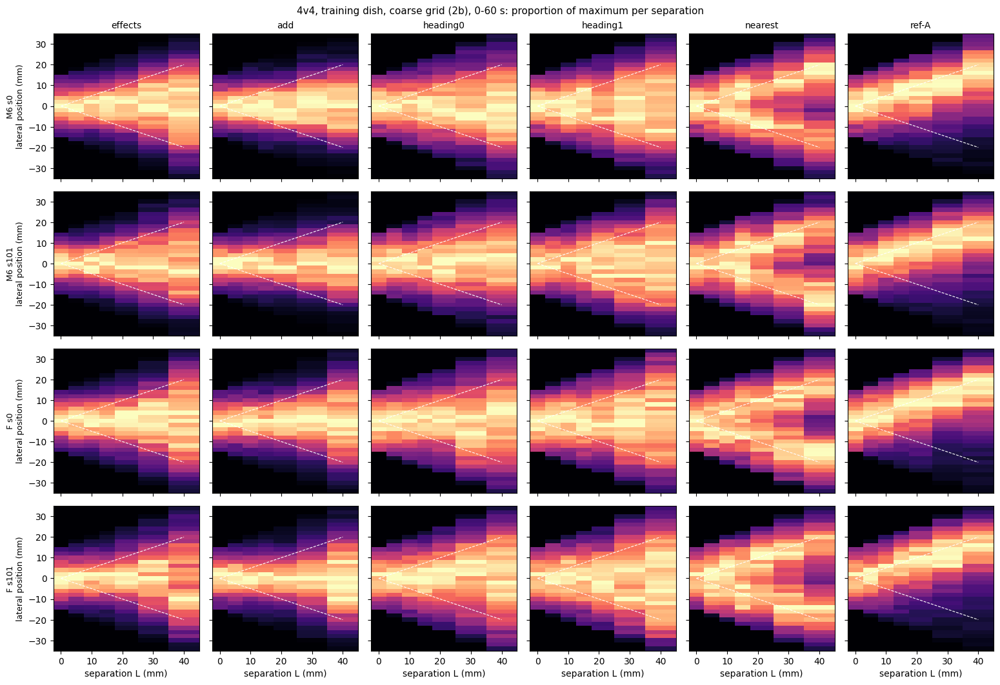

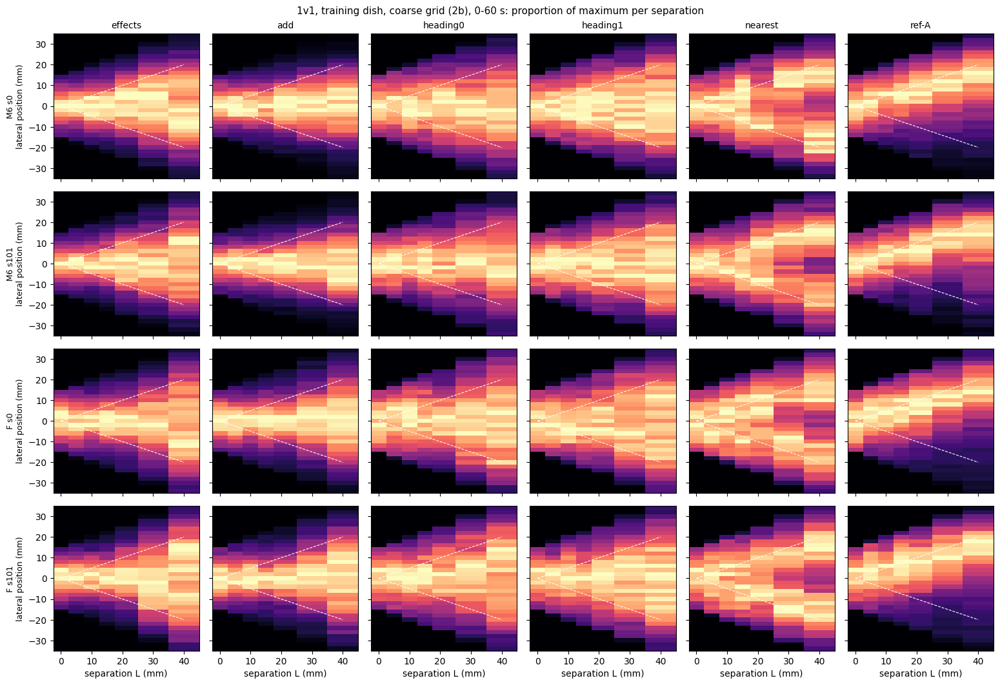

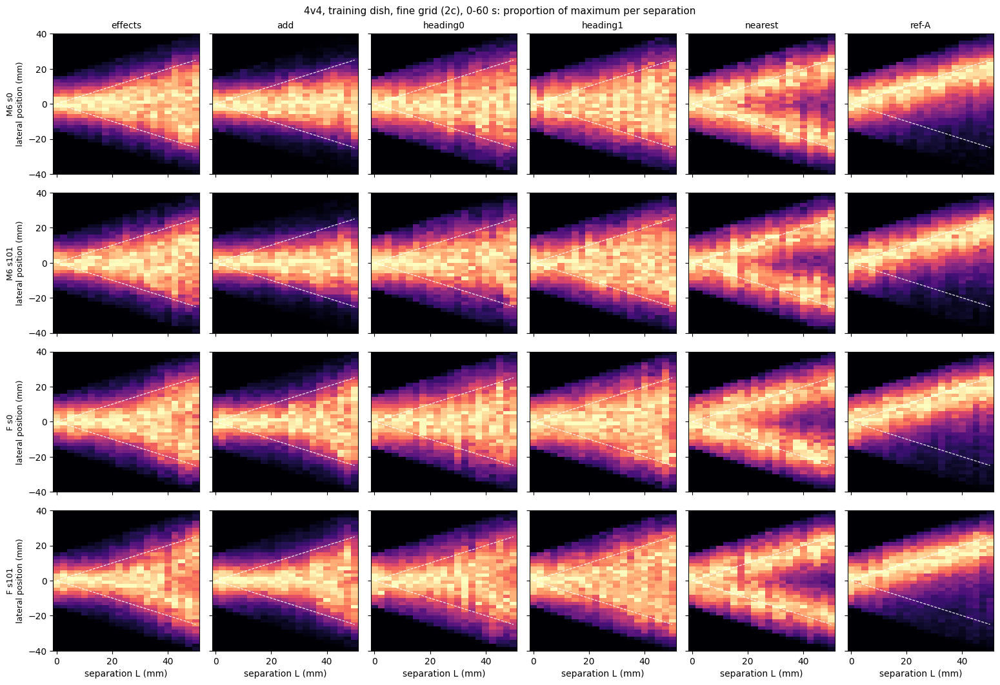

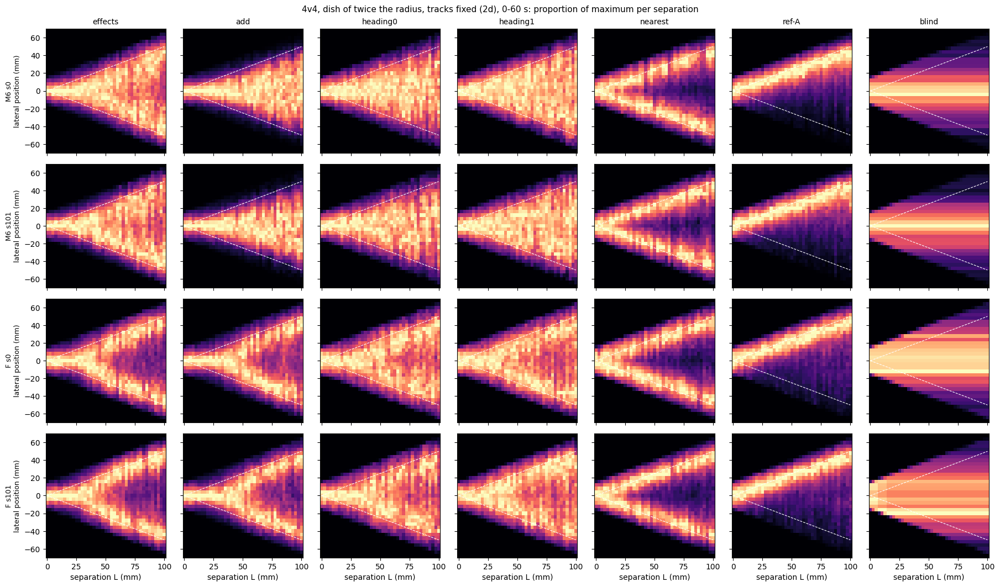

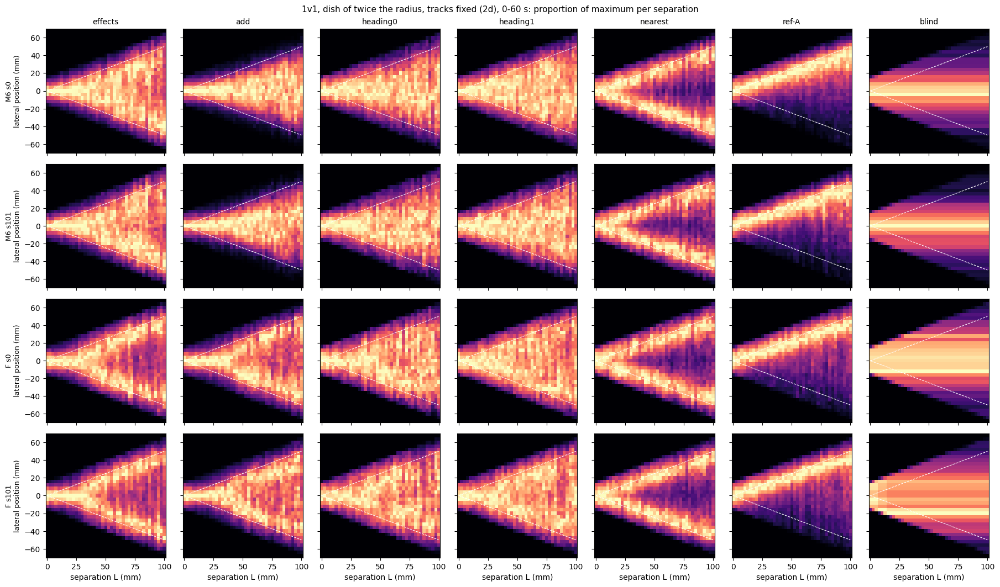

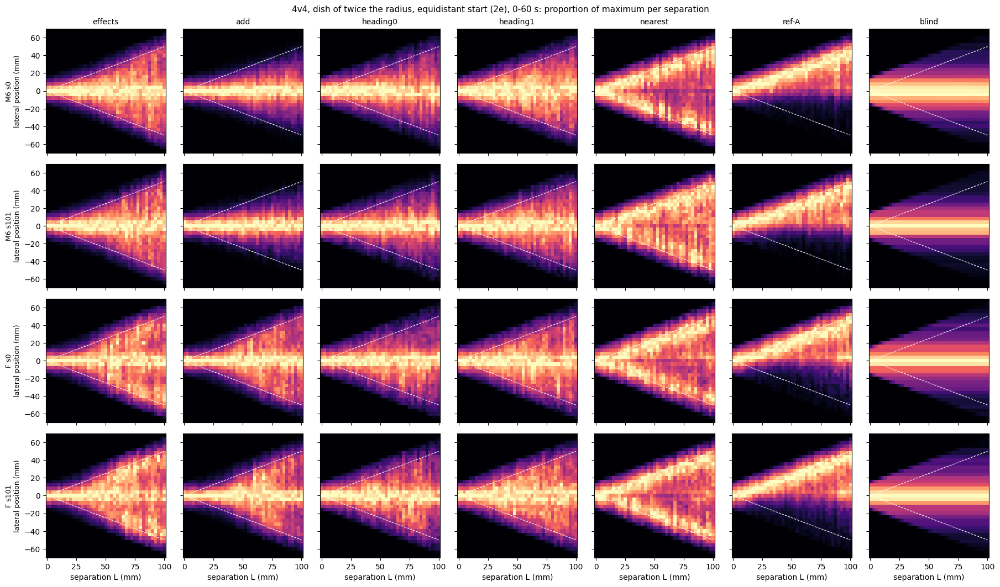

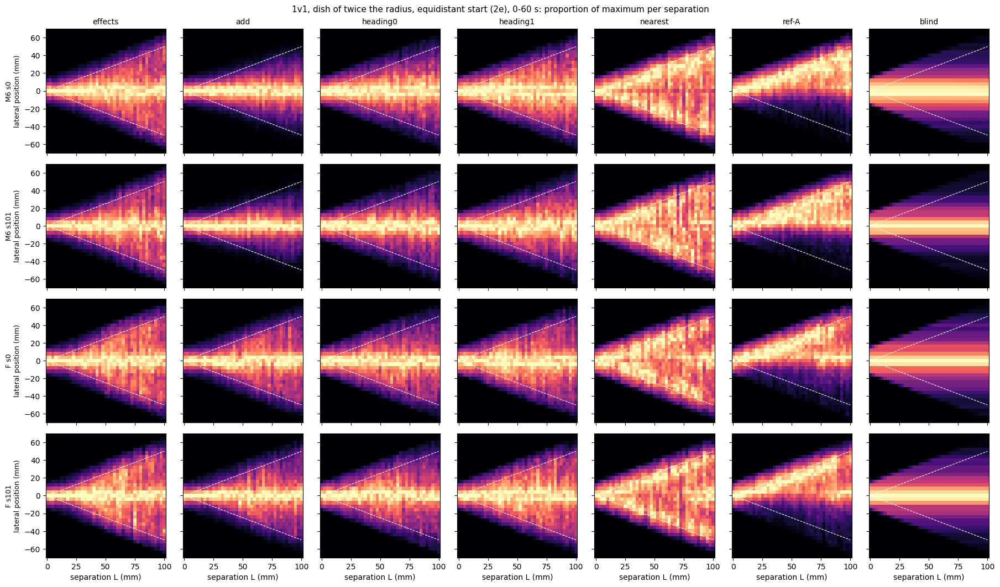

In [ ]:
def full_grid(pair, Ls, ymax, binw, arena=1, onset="free", conds=TT.FINE_CONDS, title=""):
    fig, axes = plt.subplots(len(UNITS), len(conds), figsize=(2.6 * len(conds), 2.7 * len(UNITS)), sharex=True,
                             sharey=True)
    for i, (tag, lab) in enumerate(UNITS):
        for j, c in enumerate(conds):
            ax = axes[i, j]
            bif_map(ax, tag, pair, c, Ls=Ls, ymax=ymax, binw=binw, arena=arena, onset=onset, t_min=0)
            if i == 0:
                ax.set_title(c, fontsize=10)
            if j == 0:
                ax.set_ylabel(f"{lab}\nlateral position (mm)", fontsize=9)
            if i == len(UNITS) - 1:
                ax.set_xlabel("separation L (mm)")
    fig.suptitle(f"{title}, 0-60 s: proportion of maximum per separation", fontsize=11)
    plt.tight_layout()

full_grid("4v4", TT.SEPS_MM, 35, 2.0, title="4v4, training dish, coarse grid (2b)")
full_grid("1v1", TT.SEPS_MM, 35, 2.0, title="1v1, training dish, coarse grid (2b)")
full_grid("4v4", TT.FINE_SEPS_MM, 40, 2.0, title="4v4, training dish, fine grid (2c)")
for pair in TT.BIG_PAIRS:
    full_grid(pair, TT.BIG_SEPS_MM, 70, 4.0, arena=TT.ARENA_BIG, conds=TT.BIG_CONDS,
              title=f"{pair}, dish of twice the radius, tracks fixed (2d)")
for pair in TT.BIG_PAIRS:
    full_grid(pair, TT.BIG_SEPS_MM, 70, 4.0, arena=TT.ARENA_BIG, onset="anchored", conds=TT.BIG_CONDS,
              title=f"{pair}, dish of twice the radius, equidistant start (2e)")

<a id="uneq"></a>
## 2g. Unequal pairs out to 100 mm, equidistant start

1 v 4 and 2 v 8 (A = the smaller group, on the + side of the maps; B = the larger, on the − side), in the dish of twice
the radius, L = 0–100 mm in 2.5 mm steps, with the equidistant start of 2e (at the fish's first bout of each block the
pair's midpoint 20 mm ahead, the fish on the midline: equidistant from the two group CENTROIDS); same rules (effects,
add, heading κ = 0 and 1, nearest), readout and window (20–60 s) as 2d–2e, references only A (the smaller) and only B
(the larger) shown. No blind fish: it sees no target, so it is the 4 v 4 blind run of 2e. Juvenile zebrafish prefer the
larger of two shoals at ratios like these (Sheardown et al. 2022); the question here is whether, once the fish chooses,
it chooses the larger group, and whether the averaging point is pulled toward it.

Readouts, per L: the map (as before; an asymmetric map = a preference); the **share of following bouts nearer the
larger group** (0.5 = no preference; mean over fish with a 95 % bootstrap CI, each fish the mean of its trials); the
**share of committed trials that end on the larger group** (trials with ≥ 5 following bouts and a mean lateral
offset beyond L/4, as in 2e; 0.5 = no preference); and the dip and split separation as in 2c (on positions mirrored
about the midline, so it asks whether there are two branches, not which is preferred).

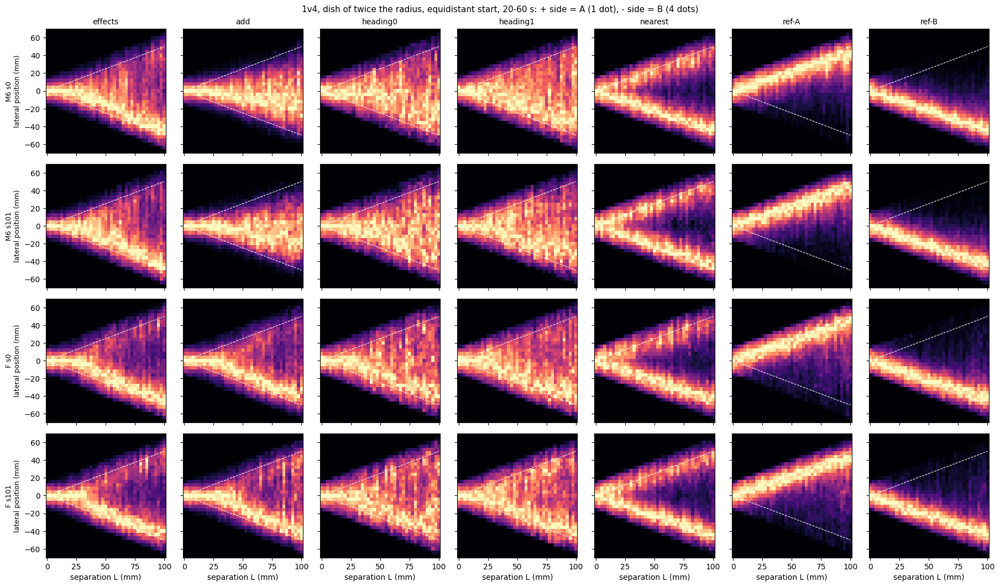

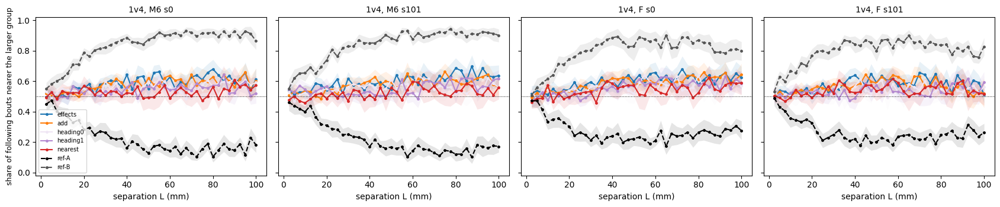

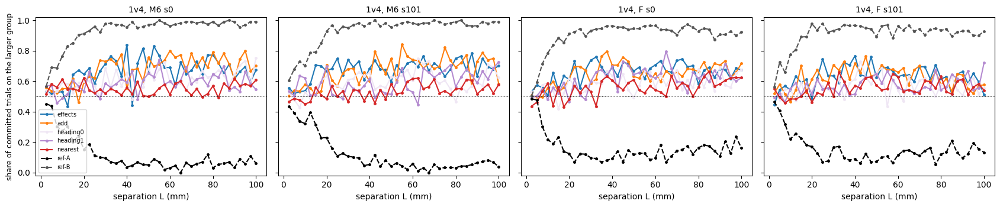

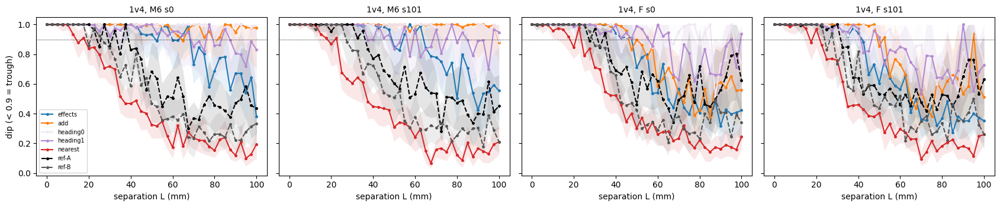

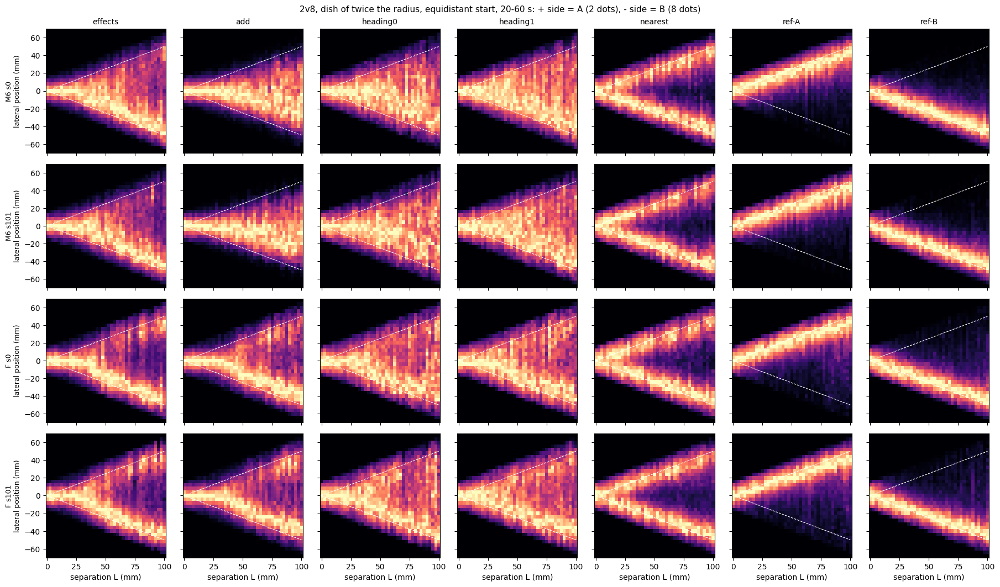

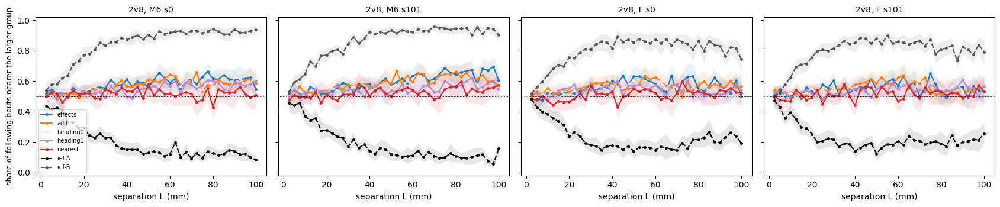

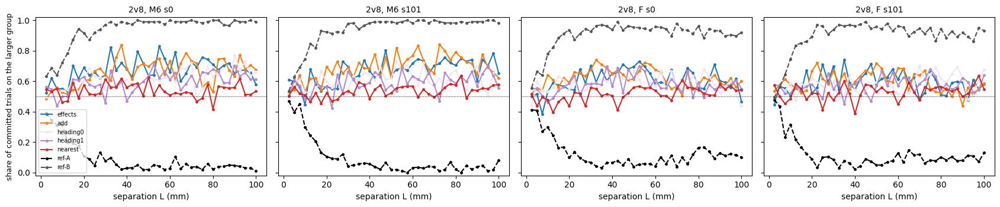

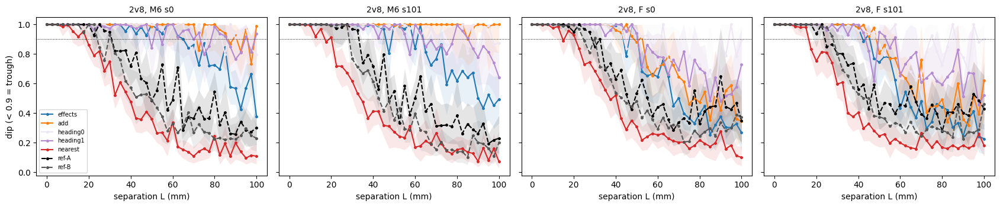

In [ ]:
conds_u = TT.UNEQ_CONDS
RCu = dict(RC)

def uneq_maps(pair):
    fig, axes = plt.subplots(len(UNITS), len(conds_u), figsize=(2.6 * len(conds_u), 2.7 * len(UNITS)), sharex=True,
                             sharey=True)
    for i, (tag, lab) in enumerate(UNITS):
        for j, c in enumerate(conds_u):
            ax = axes[i, j]
            bif_map(ax, tag, pair, c, Ls=TT.BIG_SEPS_MM, ymax=70, binw=4.0, arena=TT.ARENA_BIG, onset="anchored")
            if i == 0:
                ax.set_title(c, fontsize=10)
            if j == 0:
                ax.set_ylabel(f"{lab}\nlateral position (mm)", fontsize=9)
            if i == len(UNITS) - 1:
                ax.set_xlabel("separation L (mm)")
    a, b = TT.PAIRS[pair]
    fig.suptitle(f"{pair}, dish of twice the radius, equidistant start, 20-60 s: + side = A ({a} dot{'s' if a > 1 else ''}), "
                 f"- side = B ({b} dots)", fontsize=11)
    plt.tight_layout()

def pref_rows(tag, pair, cond):
    rows = []
    for L in TT.BIG_SEPS_MM[1:]:
        b = TT.load(tag, pair, L, cond, TT.ARENA_BIG, "anchored")
        tt = TT.trial_table(b, L)
        tt["closerB"] = 1 - tt.closerA
        m, lo, hi, _ = TT.fish_mean(tt, "closerB")
        f = TT.following(b.query("t_blk >= 20"), L)
        g = f.groupby(["fish", "blk"]).lat_mm.agg(["size", "mean"])
        g = g[(g["size"] >= 5) & (g["mean"].abs() > L / 4)]
        rows.append(dict(tag=tag, pair=pair, cond=cond, L=L, nearB=m, nearB_lo=lo, nearB_hi=hi,
                         committed=len(g), onB=float((g["mean"] < 0).mean()) if len(g) else np.nan))
    return rows

PREF = pd.DataFrame([r for pair in TT.UNEQ_PAIRS for tag, _ in UNITS for c in conds_u for r in pref_rows(tag, pair, c)])
FTu, FSu_ = {}, {}
for pair in TT.UNEQ_PAIRS:
    FTu[pair], FSu_[pair] = TT.split_table(pair=pair, arena=TT.ARENA_BIG, seps=TT.BIG_SEPS_MM, conds=conds_u,
                                           onset="anchored")

for pair in TT.UNEQ_PAIRS:
    uneq_maps(pair)
    for col, ylab, ref in (("nearB", "share of following bouts nearer the larger group", 0.5),
                           ("onB", "share of committed trials on the larger group", 0.5)):
        fig, axes = plt.subplots(1, len(UNITS), figsize=(17, 3.6), sharey=True)
        for j, (tag, lab) in enumerate(UNITS):
            ax = axes[j]
            for c in conds_u:
                g = PREF[(PREF.tag == tag) & (PREF.pair == pair) & (PREF.cond == c)].sort_values("L")
                ax.plot(g.L, g[col], "-o", ms=2.5, color=RCu[c], label=c, ls="--" if c.startswith("ref") else "-")
                if col + "_lo" in g:
                    ax.fill_between(g.L, g[col + "_lo"], g[col + "_hi"], color=RCu[c], alpha=0.10, lw=0)
            ax.axhline(ref, color="k", lw=0.7, ls=":")
            ax.set_ylim(-0.02, 1.02)
            ax.set_title(f"{pair}, {lab}", fontsize=10); ax.set_xlabel("separation L (mm)")
        axes[0].set_ylabel(ylab, fontsize=9)
        axes[0].legend(fontsize=7)
        plt.tight_layout()
    fig, axes = plt.subplots(1, len(UNITS), figsize=(17, 3.6), sharey=True)
    for j, (tag, lab) in enumerate(UNITS):
        ax = axes[j]
        for c in conds_u:
            g = FTu[pair][(FTu[pair].tag == tag) & (FTu[pair].cond == c)].sort_values("L")
            ax.plot(g.L, g.dip, "-o", ms=2.5, color=RCu[c], label=c, ls="--" if c.startswith("ref") else "-")
            ax.fill_between(g.L, g.dip_lo, g.dip_hi, color=RCu[c], alpha=0.10, lw=0)
        ax.axhline(0.9, color="k", lw=0.7, ls=":")
        ax.set_title(f"{pair}, {lab}", fontsize=10); ax.set_xlabel("separation L (mm)")
    axes[0].set_ylabel("dip (< 0.9 = trough)"); axes[0].legend(fontsize=7)
    plt.tight_layout()

In [ ]:
FSun = pd.concat([FSu_[p].assign(pair=p) for p in TT.UNEQ_PAIRS]).assign(unit=lambda d: d.tag.map(dict(UNITS)))
FSun.pivot_table(index=["pair", "cond"], columns="unit", values=["split_L", "angle_at_split", "dip_max_L"]).round(2)

              angle_at_split                         dip_max_L                      split_L                     
unit                    F s0  F s101   M6 s0 M6 s101      F s0 F s101 M6 s0 M6 s101    F s0 F s101 M6 s0 M6 s101
pair cond                                                                                                       
1v4  add              118.24  125.46     NaN     NaN      0.56   0.51  0.98    0.88    97.5   97.5   NaN     NaN
     effects          100.15   95.19  117.56  115.51      0.42   0.35  0.38    0.55    65.0   55.0  95.0    87.5
     heading0            NaN     NaN     NaN     NaN      0.74   0.74  0.90    0.89     NaN    NaN   NaN     NaN
     heading1            NaN     NaN     NaN     NaN      0.94   0.73  0.83    0.95     NaN    NaN   NaN     NaN
     nearest           60.50   54.90   60.29   54.90      0.24   0.26  0.19    0.21    30.0   25.0  27.5    25.0
     ref-A               NaN     NaN   82.27   98.16      0.62   0.63  0.43    0.45     NaN    N

In [ ]:
P2 = PREF[PREF.L.isin([20.0, 50.0, 80.0, 100.0])].assign(unit=lambda d: d.tag.map(dict(UNITS)))
P2.pivot_table(index=["pair", "cond"], columns=["unit", "L"], values="nearB").round(2)

unit           F s0                   F s101                   M6 s0                   M6 s101                  
L             20.0  50.0  80.0  100.0  20.0  50.0  80.0  100.0 20.0  50.0  80.0  100.0   20.0  50.0  80.0  100.0
pair cond                                                                                                       
1v4  add       0.54  0.58  0.61  0.64   0.55  0.59  0.56  0.52  0.52  0.62  0.63  0.60    0.56  0.59  0.61  0.56
     effects   0.54  0.60  0.58  0.62   0.50  0.59  0.55  0.51  0.55  0.55  0.68  0.61    0.54  0.55  0.69  0.64
     heading0  0.54  0.52  0.64  0.57   0.51  0.58  0.55  0.56  0.55  0.59  0.57  0.59    0.55  0.61  0.52  0.56
     heading1  0.49  0.57  0.57  0.59   0.53  0.57  0.53  0.59  0.52  0.57  0.57  0.52    0.57  0.52  0.53  0.62
     nearest   0.50  0.57  0.52  0.59   0.49  0.54  0.60  0.52  0.57  0.49  0.56  0.57    0.49  0.56  0.54  0.56
     ref-A     0.30  0.22  0.26  0.28   0.33  0.20  0.25  0.26  0.28  0.13  0.10  0.18    0.31  

In [ ]:
P2.pivot_table(index=["pair", "cond"], columns=["unit", "L"], values="onB").round(2)

unit           F s0                   F s101                   M6 s0                   M6 s101                  
L             20.0  50.0  80.0  100.0  20.0  50.0  80.0  100.0 20.0  50.0  80.0  100.0   20.0  50.0  80.0  100.0
pair cond                                                                                                       
1v4  add       0.62  0.63  0.66  0.72   0.61  0.64  0.58  0.58  0.59  0.76  0.79  0.70    0.71  0.75  0.69  0.58
     effects   0.61  0.67  0.58  0.67   0.48  0.62  0.62  0.51  0.65  0.66  0.77  0.67    0.67  0.59  0.75  0.70
     heading0  0.62  0.49  0.68  0.68   0.54  0.65  0.58  0.56  0.60  0.68  0.64  0.75    0.64  0.63  0.47  0.62
     heading1  0.46  0.64  0.62  0.62   0.52  0.65  0.54  0.72  0.53  0.65  0.65  0.55    0.70  0.51  0.56  0.73
     nearest   0.48  0.61  0.56  0.62   0.46  0.57  0.63  0.54  0.62  0.50  0.57  0.61    0.48  0.58  0.55  0.58
     ref-A     0.12  0.12  0.16  0.16   0.17  0.07  0.12  0.13  0.15  0.05  0.03  0.06    0.23  

<a id="dist"></a>
## 3. Where the fish sits: distributions

The lateral offset of following bouts from the midline (mm, 20–60 s), 4 v 4, at L = 20, 30 and 40 mm, seed 0 (seed 101
below); dotted, the two tracks at ±L/2. **Averaging** = one peak at 0; **choosing** = two peaks at ±L/2. Last two columns:
the midline follower and the fish shown only A on the same scale.

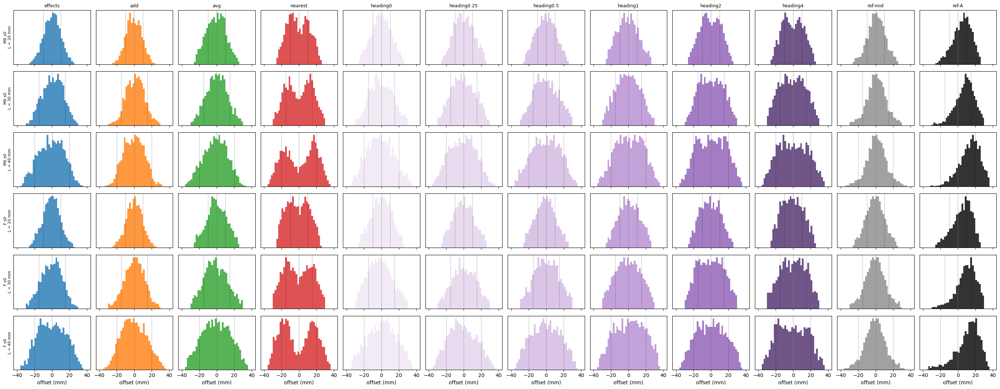

In [ ]:
def dist_grid(tags, pair="4v4", Ls=(20, 30, 40)):
    conds = TT.RULES + ("ref-mid", "ref-A")
    fig, axes = plt.subplots(len(tags) * len(Ls), len(conds), figsize=(2.3 * len(conds), 1.8 * len(tags) * len(Ls)),
                             sharex=True)
    bins = np.linspace(-40, 40, 41)
    for ti, (tag, lab) in enumerate(tags):
        for li, L in enumerate(Ls):
            r = ti * len(Ls) + li
            for c_i, c in enumerate(conds):
                ax = axes[r, c_i]
                b = TT.load(tag, pair, 0, "ref-A") if c == "ref-mid" else TT.load(tag, pair, L, c)
                f = TT.following(b[b.t_blk >= 20], L)
                ax.hist(f.lat_mm, bins=bins, color=RC[c], alpha=0.8, density=True)
                ax.axvline(0, color="grey", lw=0.5)
                for v in (L / 2, -L / 2):
                    ax.axvline(v, color="k", lw=0.5, ls=":")
                ax.set_yticks([])
                if r == 0:
                    ax.set_title(c, fontsize=9)
                if c_i == 0:
                    ax.set_ylabel(f"{lab}\nL = {L} mm", fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("offset (mm)")
    plt.tight_layout()

dist_grid([("26e", "M6 s0"), ("14f", "F s0")])

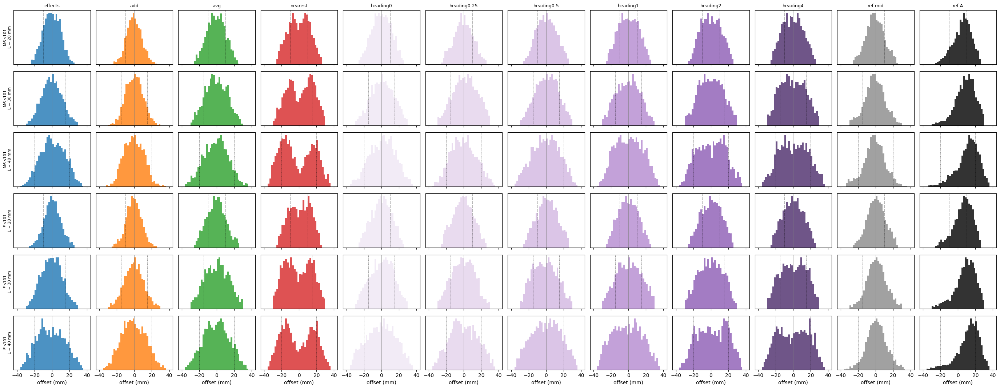

In [ ]:
dist_grid([("30d", "M6 s101"), ("32b", "F s101")])

<a id="asym"></a>
## 4. Unequal targets: 1 v 4 and 2 v 8

A is the smaller group. Top: the share near the midline (the bifurcation curve, comparable with section 2), with the midline follower and the
fish shown only A. Middle: the mean signed offset (mm, + toward A, the smaller group; negative = the averaging point or
the choice is shifted toward the larger group B). Bottom: the share of following bouts closer to the larger group (0.5 =
no preference). Dashed: only A shown (black), only B shown (dark grey). Zebrafish prefer the
larger shoal when the ratio is large (juveniles: 1 v 3, 2 v 3, 2 v 5; Sheardown et al. 2022), so a fish-like model should
favour B, increasingly so once it chooses.

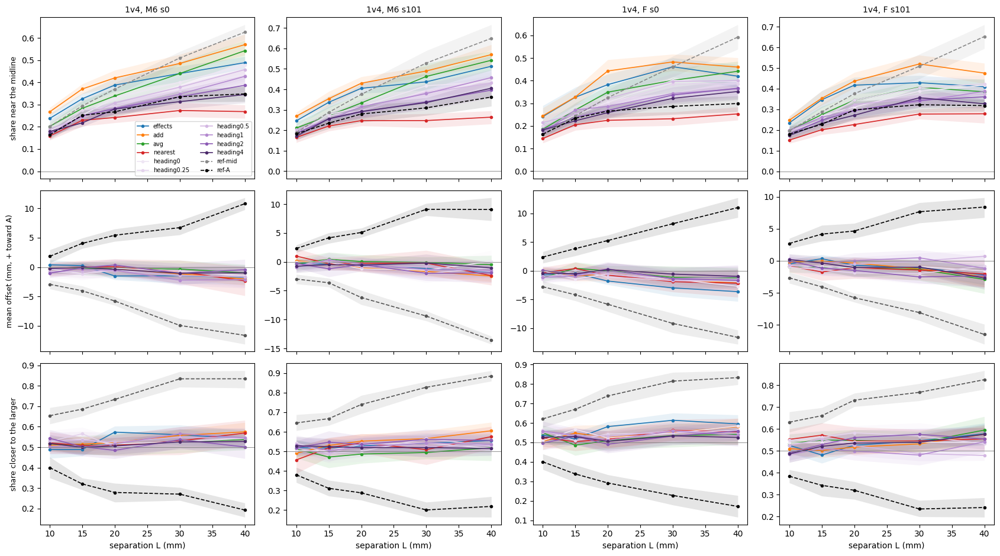

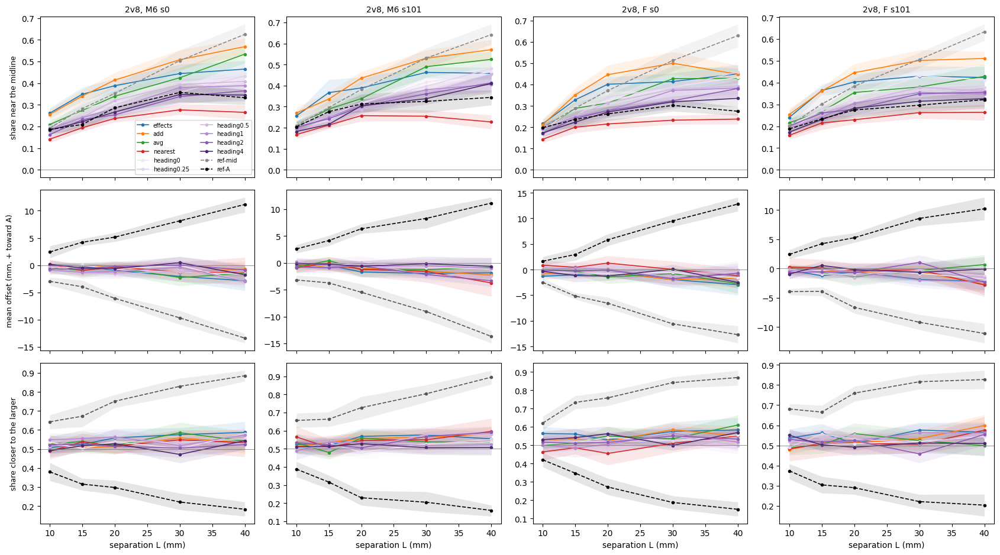

In [ ]:
S = S.assign(closerB=1 - S.closerA, closerB_lo=1 - S.closerA_hi, closerB_hi=1 - S.closerA_lo)
for pair in ("1v4", "2v8"):
    fig, axes = plt.subplots(3, 4, figsize=(17, 9.5), sharex=True)
    for j, (tag, lab) in enumerate(UNITS):
        for i, (col, ylab) in enumerate((("middle", "share near the midline"), ("lat", "mean offset (mm, + toward A)"),
                                         ("closerB", "share closer to the larger"))):
            ax = axes[i, j]
            curve(ax, S, tag, pair, col=col, refs=(("ref-mid", "ref-A") if col == "middle" else ("ref-A", "ref-B")))
            ax.axhline(0.5 if col == "closerB" else 0, color="grey", lw=0.6)
            if j == 0:
                ax.set_ylabel(ylab, fontsize=9)
            if i == 0:
                ax.set_title(f"{pair}, {lab}", fontsize=10)
            if i == 2:
                ax.set_xlabel("separation L (mm)")
    axes[0, 0].legend(fontsize=7, ncol=2)
    plt.tight_layout()

<a id="onset"></a>
## 5. The onset window (0–20 s)

The same curve in the first 20 s of each block, while the fish is still approaching and F's correction is on: does the
fish already commit during the approach?

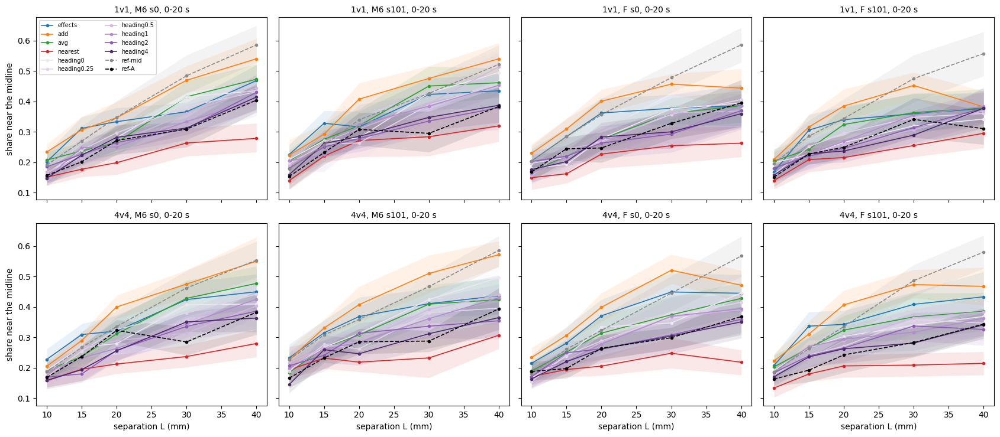

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharex=True, sharey=True)
for i, pair in enumerate(("1v1", "4v4")):
    for j, (tag, lab) in enumerate(UNITS):
        ax = axes[i, j]
        curve(ax, S1, tag, pair, col="middle")
        ax.set_title(f"{pair}, {lab}, 0-20 s", fontsize=10)
        if i == 1:
            ax.set_xlabel("separation L (mm)")
        if j == 0:
            ax.set_ylabel("share near the midline")
axes[0, 0].legend(fontsize=7, ncol=2)
plt.tight_layout()

<a id="numbers"></a>
## 6. Numbers

The commitment index (20–60 s) at 20, 30 and 40 mm per pair, rule and unit (0 = the midline follower, 1 = the fish shown
only A), then the share near the midline with both references.

In [ ]:
lab = dict(UNITS)
T = S[S.L.isin([20, 30, 40]) & S.cond.isin(TT.RULES)].assign(unit=lambda d: d.tag.map(lab))
T.pivot_table(index=["pair", "cond"], columns=["unit", "L"], values="commit").round(2)

unit              F s0             F s101             M6 s0             M6 s101            
L                   20    30    40     20    30    40    20    30    40      20    30    40
pair cond                                                                                  
1v1  add         -1.46 -0.06  0.35  -0.44  0.20  0.46 -0.71 -0.25  0.07   -0.60 -0.11  0.12
     avg          0.04  0.34  0.49   0.87  0.54  0.72  0.29  0.46  0.40    0.37  0.27  0.43
     effects     -1.02  0.06  0.66  -0.25  0.51  0.88 -0.14  0.45  0.53   -0.08  0.30  0.72
     heading0     0.13  0.73  0.66   0.74  0.63  0.82  0.79  0.68  0.58    0.28  0.55  0.74
     heading0.25  0.44  0.61  0.62   0.71  0.85  0.94  0.57  0.76  0.66    0.46  0.67  0.78
     heading0.5   0.51  0.76  0.67   0.73  0.75  0.84  0.37  1.00  0.77    0.55  0.68  0.72
     heading1     0.92  0.91  0.71   0.83  0.67  0.79  0.75  0.83  0.76    0.83  0.72  1.01
     heading2     0.85  0.81  0.92   1.00  0.96  0.86  0.91  0.95  0.97    0.62 

In [ ]:
M = S[S.L.isin([20, 30, 40])].assign(unit=lambda d: d.tag.map(lab))
M.pivot_table(index=["pair", "cond"], columns=["unit", "L"], values="middle").round(2)

unit              F s0             F s101             M6 s0             M6 s101            
L                   20    30    40     20    30    40    20    30    40      20    30    40
pair cond                                                                                  
1v1  add          0.42  0.47  0.47   0.44  0.48  0.49  0.42  0.51  0.58    0.43  0.52  0.59
     avg          0.33  0.42  0.45   0.32  0.40  0.42  0.32  0.43  0.49    0.32  0.45  0.53
     effects      0.40  0.45  0.39   0.40  0.40  0.38  0.35  0.42  0.45    0.36  0.44  0.45
     heading0     0.32  0.36  0.40   0.30  0.41  0.39  0.28  0.40  0.46    0.33  0.41  0.46
     heading0.25  0.30  0.38  0.41   0.32  0.35  0.38  0.31  0.38  0.44    0.35  0.38  0.44
     heading0.5   0.29  0.35  0.38   0.31  0.37  0.39  0.31  0.35  0.41    0.29  0.39  0.45
     heading1     0.27  0.32  0.37   0.32  0.37  0.41  0.28  0.36  0.40    0.28  0.37  0.39
     heading2     0.28  0.32  0.34   0.27  0.32  0.39  0.27  0.35  0.37    0.31 

<a id="reading"></a>
## 7. What it shows

**What can be read.** A fish following one target wanders 6–7 mm to either side of it, so below about 15 mm of separation
averaging and choosing give the same distribution (the two references coincide at 10 mm). The informative range is
20–40 mm. The split itself needs larger separations than the training dish holds (section 2d).

**effects (motor summation) shows the documented pattern.** At 20 mm its share of following bouts near the midline equals
the midline follower's (0.37–0.42 against 0.37–0.38, 4 v 4, every unit): it averages. By 30–40 mm it has left the averaging
state (0.42–0.50 against 0.65–0.66 for the midline follower and 0.30–0.34 for a committed fish), about halfway to
committed, with a third of its following bouts near a track at 40 mm against a fifth for the midline follower. So summing
the two groups' effects gives averaging at small separation and a move toward choosing at large separation — the
qualitative behaviour of zebrafish following two virtual conspecifics (Sridhar et al. 2021) — but the move is gradual over
20–40 mm, not an abrupt switch, and does not reach full commitment by 40 mm. *add* behaves similarly but commits less (M6
hardly at all by 40 mm). The pattern holds at both seeds of both models and for 1 v 1 as for 4 v 4.
The distributions (2c) show that up to 50 mm this move is a band that BROADENS with its peak still on the midline,
not yet two branches; the branches appear beyond 50 mm (2d).

**Where each rule splits (sections 2c and 2d).** The split = the separation from which the midline becomes a clear
trough between two branches. At both seeds of both models:

| | training dish, 4 v 4 (L ≤ 50 mm) | 2x dish, 4 v 4 | 2x dish, 1 v 1 |
|---|---|---|---|
| **effects** | no split (dip 0.84–1.00 at 50 mm) | F 57.5 / 52.5 mm (≈ 95°), M6 85 / 85 mm (117–122°) | F 62.5 / 52.5 mm (97–100°), M6 97.5 / 97.5 mm (118–121°) |
| add | no split | F 57.5 / 57.5 mm (106°), M6 none | none (F s101 at 100 mm) |
| heading κ = 0 / 1 | no split | late or none (72.5–100 mm), shallow trough (dip 0.59–0.92 at 100 mm) | none, except at 100 mm |
| nearest | 25–27.5 mm (57–61°) | 22.5–27.5 mm (51–55°) | 25–30 mm (50–60°) |
| only A shown (floor) | 37.5–50 mm | 35–47.5 mm | 67.5–100 mm or none (a one-dot target is followed loosely) |

(seed 0 / seed 101; in brackets the median angle the two targets subtend at the following fish at the split.)

- **effects is Sridhar's pitchfork**: one band on the midline (it broadens as L grows, but the midline stays the peak)
  up to about 50 mm, then two branches that deepen with separation (dip 0.23–0.27 at 100 mm in F, deeper than the
  one-target reference's 0.40). In F the split comes at 52.5–62.5 mm, where the two targets subtend about 95–100° at the
  fish; in M6 later, at 85–97.5 mm and 117–122°. The seeds agree within each model (F 57.5 | 52.5, M6 85 | 85 for 4 v 4).
  For comparison, the paper's zebrafish average at a lateral distance of 6 cm and choose at 8–11 cm (Oscar et al. 2023,
  the same data), and its model switches at about 90°; flies at about 110°, locusts at about 90°. Their fish are larger
  and faster, so the distances in mm are not comparable; the angle is the comparable quantity, and F's 95–100° is close.
- **add** behaves like effects in F (split at 57.5 mm) and does not split in M6.
- **heading** (any κ) broadens without splitting: the band spreads from the start, but the midline stays nearly as dense
  as the branches (a shallow trough at best, late). Averaging the two effects weakens each target's pull, so the fish
  follows neither tightly.
- **nearest** splits as soon as two branches can be resolved (22.5–30 mm, about 55°): it chooses from the start.
- **The training dish (L ≤ 50 mm) is too small to see the effects split**: only nearest splits there. The earlier
  reading of the fine map (effects 'splits' at 17.5–27.5 mm, heading 'chooses from the start') used the rise of μ, which a
  band that only broadens also produces; it is superseded by the trough criterion.
- **The larger dish does not make the split.** The blind fish keeps one band at every separation (dip 0.97–1.00), and
  in the training dish's range (L ≤ 50 mm) the dip is the same in both dishes (last panel of 2d).
- **Nor does where the fish starts (2e).** With every block anchored so that the fish starts exactly on the midline,
  equidistant from both groups, effects still splits at the same separations in 4 v 4 (F 50 | 55 mm, about 90°; M6 95 |
  87.5 mm, about 120°), to the same depth, and the committed fish end on A and B equally: the symmetry is broken by the
  fish, as in the theory. In 1 v 1 the F split holds at seed 0 (62.5 mm) but moves to 97.5 mm at seed 101 (a weaker
  trough), and heading's late troughs disappear (they were inherited from the start position).

**heading, on the coarse readouts (section 2).** κ = 1–4 sits on the one-target curve already at 20 mm by the share near
the midline, κ = 0.25–0.5 nearly so; the distributions (2c, 2d) show this is a broad band rather than two branches. The κ = 0 control, the plain average of the two effects, is already halfway committed at 20 mm:
most of the shift comes from AVERAGING the effects instead of summing them (each target's pull is halved), not from the
heading feedback. Whether real zebrafish switch below or above 20 mm is not reported (Sridhar et al. give no critical
separation for fish), so these results do not rank effects against heading; they show that the separation of the switch
depends on how the two pulls are combined.

**nearest** chooses at every separation (below the one-target curve throughout), so it never averages. **avg** (averaged
stimulus columns) gives broad distributions that are neither averaging nor choosing: the averaged input is a stimulus
direction the models never saw.

**Unequal targets.** No rule produces a clear preference for the larger group: the share of following closer to it stays
at 0.50–0.61 under every rule (references: 0.17–0.30 with only the smaller group shown, 0.73–0.89 with only the larger),
the weak excess growing slightly with separation for effects and add. Juvenile zebrafish prefer the larger shoal at ratios
like these (Sheardown et al. 2022), so here the models fall short. The bifurcation curves of 1 v 4 and 2 v 8 resemble those
of the identical pairs.

**Caveats.** The targets move straight at 2 mm/s on tracks fixed in the dish, so block onsets are not placed as in the rig
(the pair is 22.7 mm away at the first bout, median; 31 % of blocks start beyond 30 mm), which is why the main window
starts at 20 s; the 0–20 s curves are shown but not interpreted. Dots in training moved on their own paths, so a centroid
moving straight is a cleaner trajectory than any the models saw, though within the trained input range.

<a id="video"></a>
## 8. A video of the experiment

One simulated fish (F, seed 0, rule *effects*, 4 v 4, the dish of twice the radius), the SAME fish and the same block
at three separations, side by side: same start, latent, drift, random streams and tracks; only L differs. Red and blue:
the two dot groups, moving in step back and forth along their tracks at 2 mm/s (each group drawn as 4 dots around its
centroid; the model sees only the centroid, the count and the moving flag); black: the fish with a 10 s trail; dashed:
the midline. Below each dish, the fish's lateral position over the block, with the two tracks at ±L/2: near 0 = between
the groups, near ±L/2 = on one group. At **20 mm** the fish stays on the midline, between the groups (averaging); at **50
mm** it drifts onto group B's track for most of the block (the split separation of F, section 2d); at **80 mm** it
settles on group B within the first 20 s and follows it to the end of the block (choosing). Time runs at ×3; the
readout window (20–60 s) is marked.

**This is an illustration, not a random sample**: the fish and block were chosen (`scripts/two_targets_video.py`, `pick`)
as the clearest of the 150 trials: following bouts closest to the midline at 20 mm and closest to one track at 80 mm.
The re-simulation reproduces the stored run bout for bout (checked). The distributions over all fish are in sections 2c
and 2d.

**How the experiment compares with Sridhar et al. (2021)** (details in 2d): the same design — two targets moving in step,
parallel, back and forth with U-turns, at a fixed lateral separation; only bouts behind the targets are read; the
lateral distribution is stacked across separations, each normalised to its own maximum. The differences: dot groups
seen as centroids instead of images of fish (1 v 1 is the closer analogue; this video is 4 v 4, where the pattern is
clearest), 2 mm/s instead of 4–7 cm/s (in both the targets move at about the follower's own speed), legs of 40 mm (20
s) between U-turns instead of 6–8 s, the trained 60 s blocks with pauses and L fixed per run instead of a 90 min
session of trials with L re-drawn at random from trial to trial, a dish of twice the trained radius, and larval fish of unknown age instead of 24–26 dpf juveniles. So the
split is compared by the angle the two targets subtend at the fish, not in mm.

<video src="two_targets/videos/two_targets_4v4_14f_effects.mp4" controls width="980"></video>

<a id="video-anch"></a>
### 8b. The same with an equidistant start

As above (F, seed 0, rule *effects*, 4 v 4, the dish of twice the radius), from the runs of section 2e: at the fish's
first bout of each block the pair is placed 20 mm ahead of it, **the fish exactly on the midline, equidistant from both
groups** (the lateral traces all start at 0); before that bout the pair is drawn held at its start position (the model
sees the targets only at its bouts), and the view is centred on the tracks. At **20 mm** the fish stays around the
midline between the groups; at **50 mm** it wanders, then settles on group B's track from about 20 s; at **80 mm** it
moves onto group A within about 8 s and follows it to the end of the block. From the same symmetric start it ends on B
at 50 mm and on A at 80 mm: which group is not inherited from the start; the fish breaks the symmetry itself.

Again **an illustration, not a random sample**: the fish and block were chosen by the same rule as above, among the
150 equidistant-start trials (here fish 12, block 6), and the re-simulation reproduces the stored run bout for bout.

<video src="two_targets/videos/two_targets_4v4_14f_effects_anch.mp4" controls width="980"></video>

<a id="report-maps"></a>
## 9. The report maps

The bifurcation maps for the report: M6 and F at both seeds (rows), the dish of twice the radius, L = 0–100 mm in
2.5 mm steps, the **equidistant start** of 2e, for 1 v 1, 4 v 4, 1 v 4 and 2 v 8 (A = the smaller group of an unequal
pair, on the + side), under effects, add, avg and nearest and for the two references, only A shown and no target shown
(blind). Each column is the distribution of the lateral position of the **following bouts** (behind the pair, within
40 mm, and within L/2 + 15 mm of the midline; outside that, the dark triangles, nothing is read), normalised to its own
maximum (proportion of maximum), drawn in the paper's colour scheme (MATLAB's *parula*, approximated from its colour
stops; Sridhar et al. 2021, Fig. 3C); dashed, the two tracks at ±L/2. No split marks (the split criterion is in 2c–2e).
Each pair twice: 20–60 s (after the onset approach) and 0–60 s (the whole block; the anchoring bout itself, at 0 by
construction, left out). The blind runs see no target, so they do not depend on the group sizes: the 1 v 4 and 2 v 8
rows use the 4 v 4 blind run. *avg* (stimulus columns averaged) was run for these maps only. Saved as PDF in
`Model/two_targets/figs/` (`report_map_<pair>_<window>_following.pdf`).

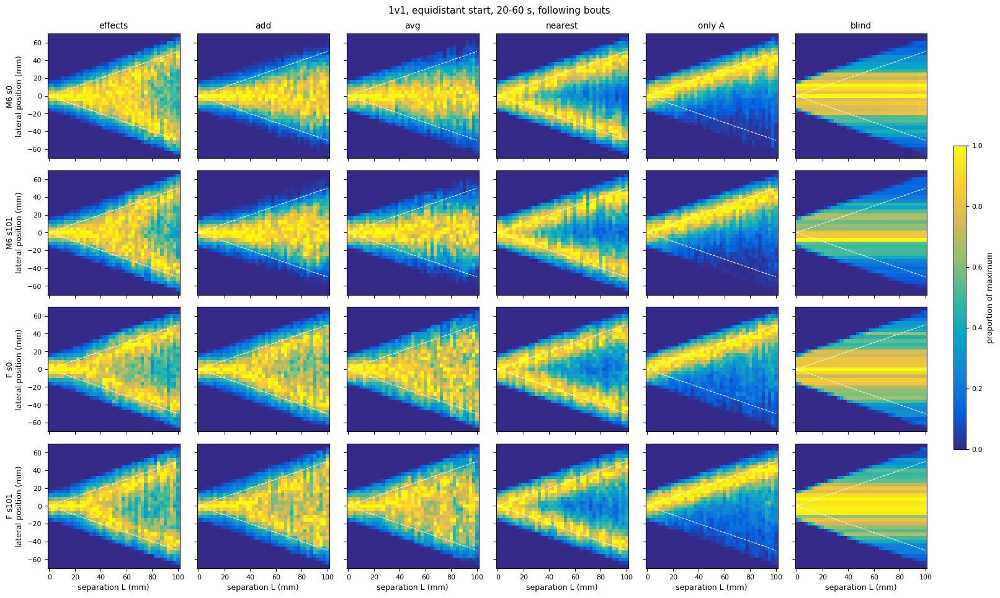

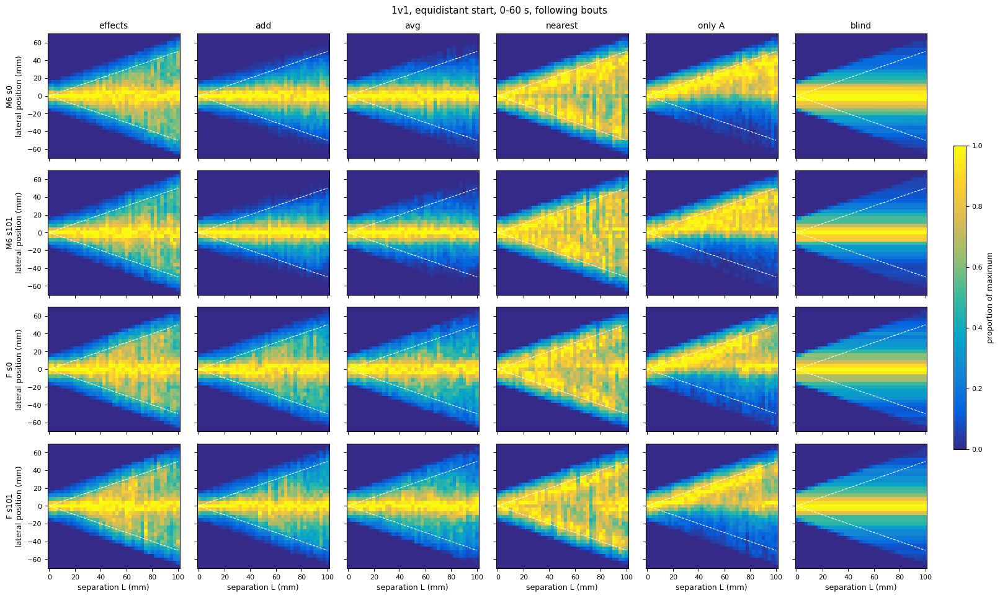

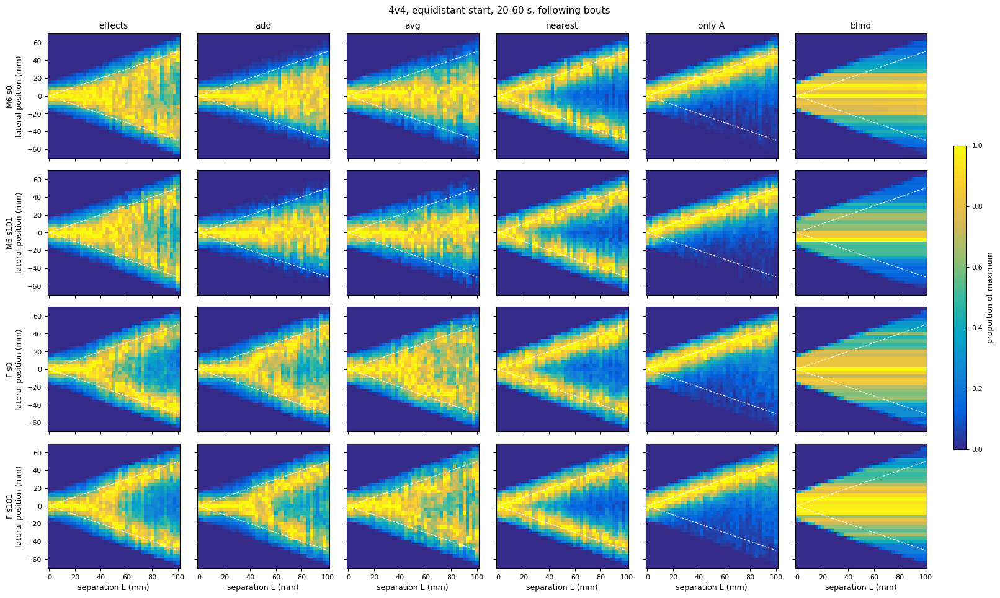

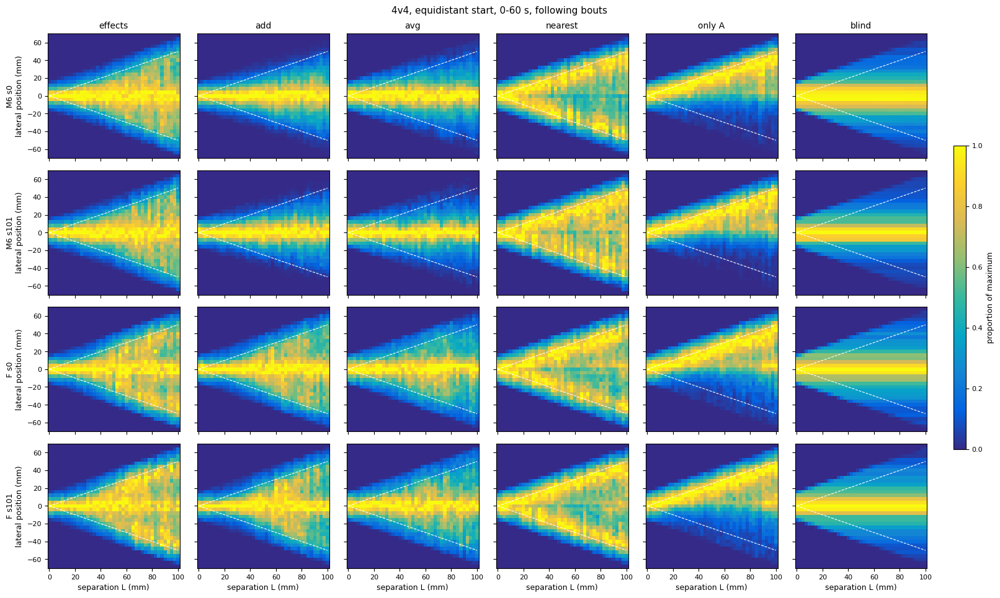

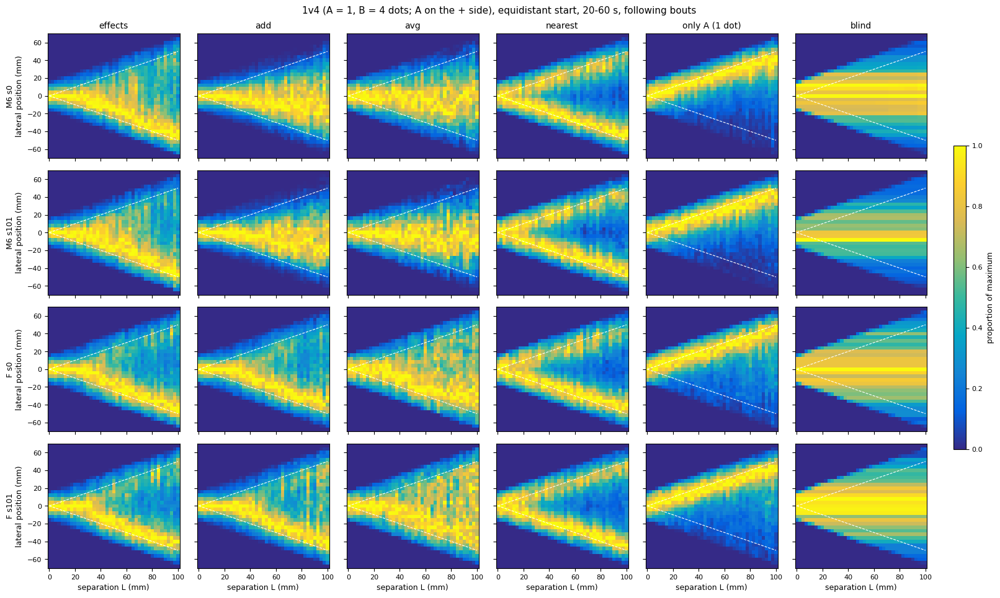

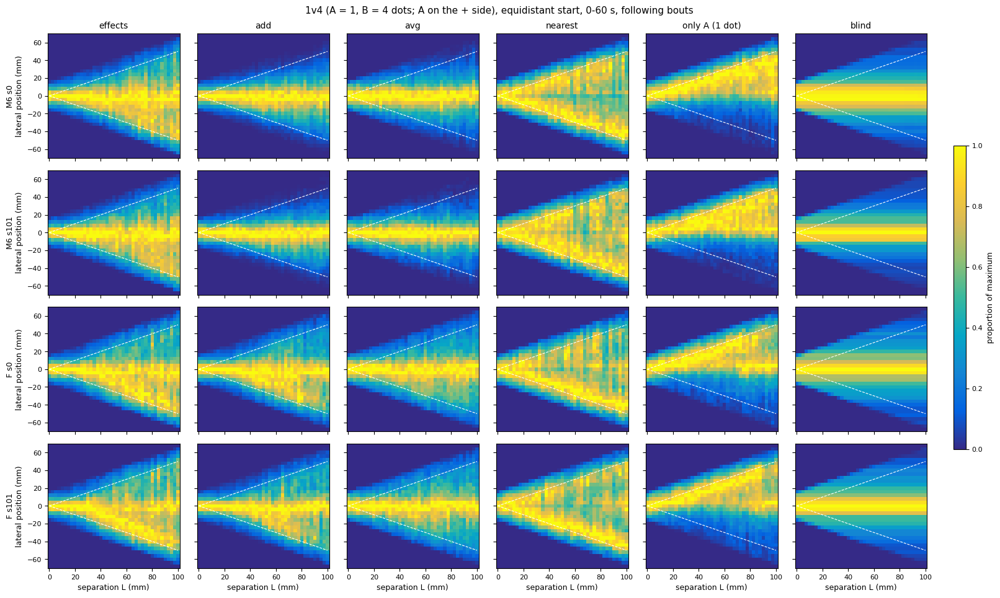

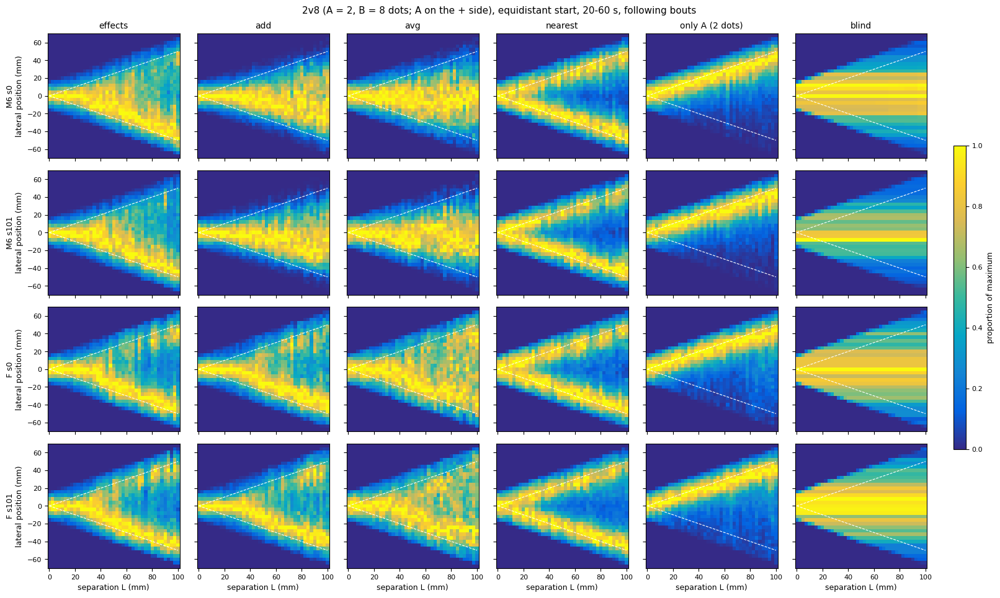

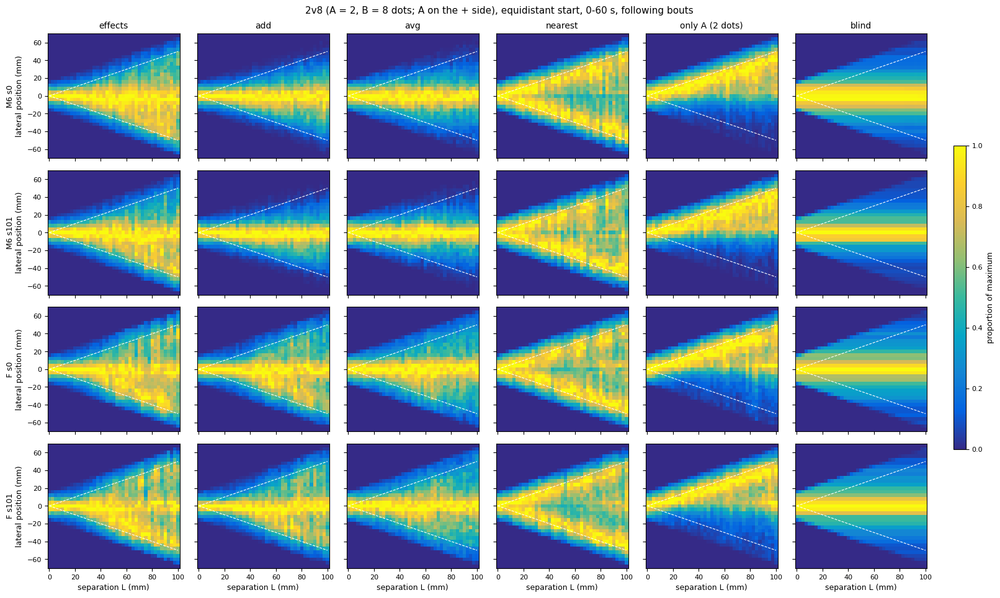

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
PARULA = LinearSegmentedColormap.from_list("parula", ["#352a87", "#0363e1", "#1485d4", "#06a7c6", "#38b99e",
                                                      "#92bf73", "#d9ba56", "#fcce2e", "#f9fb0e"])
FIGS = TT.OUT / "figs"; FIGS.mkdir(parents=True, exist_ok=True)
COLS_R = TT.REPORT_CONDS
COL_LAB = {"effects": "effects", "add": "add", "avg": "avg", "nearest": "nearest", "blind": "blind"}

def report_map(pair, t_min, select="following"):
    a, b = TT.PAIRS[pair]
    lab_a = "only A" + ("" if a == b else f" ({a} dot{'s' if a > 1 else ''})")
    fig, axes = plt.subplots(len(UNITS), len(COLS_R), figsize=(2.55 * len(COLS_R) + 0.9, 2.45 * len(UNITS)),
                             sharex=True, sharey=True)
    for i, (tag, lab) in enumerate(UNITS):
        for j, c in enumerate(COLS_R):
            ax = axes[i, j]
            src = "4v4" if (c == "blind" and a != b) else pair
            mesh = bif_map(ax, tag, src, c, Ls=TT.BIG_SEPS_MM, ymax=70, binw=4.0, arena=TT.ARENA_BIG, onset="anchored",
                           t_min=t_min, cmap=PARULA, track_col="w", select=select)
            if i == 0:
                ax.set_title(lab_a if c == "ref-A" else COL_LAB[c], fontsize=10)
            if j == 0:
                ax.set_ylabel(f"{lab}\nlateral position (mm)", fontsize=9)
            if i == len(UNITS) - 1:
                ax.set_xlabel("separation L (mm)", fontsize=9)
            ax.tick_params(labelsize=8)
    win = "20-60 s" if t_min == 20 else "0-60 s"
    pair_txt = f"{pair}" + ("" if a == b else f" (A = {a}, B = {b} dots; A on the + side)")
    sel = {"following": "following bouts", "behind": "bouts behind the pair", "all": "all bouts"}[select]
    fig.suptitle(f"{pair_txt}, equidistant start, {win}, {sel}", fontsize=11)
    fig.tight_layout(rect=(0, 0, 0.94, 1))
    cax = fig.add_axes([0.952, 0.25, 0.012, 0.5])
    cb = fig.colorbar(mesh, cax=cax); cb.set_label("proportion of maximum", fontsize=9); cb.ax.tick_params(labelsize=8)
    tagf = {"following": "following", "behind": "behind", "all": "allbouts"}[select]
    fig.savefig(FIGS / f"report_map_{pair}_{'20-60' if t_min == 20 else '0-60'}_{tagf}.pdf", bbox_inches="tight")

for pair in TT.REPORT_PAIRS:
    for t_min in (20, 0):
        report_map(pair, t_min)

<a id="report-maps-all"></a>
### 9b. The same maps with every bout

As section 9, but each column counts **every bout** of the window, with no following selection: neither the "behind
the pair" condition nor the L/2 + 15 mm lateral cut, so the maps have no empty triangles by construction (with the
equidistant start every block begins with the fish between the groups). Bouts beyond ±70 mm fall outside the plotted
range. Saved as `report_map_<pair>_<window>_allbouts.pdf`.

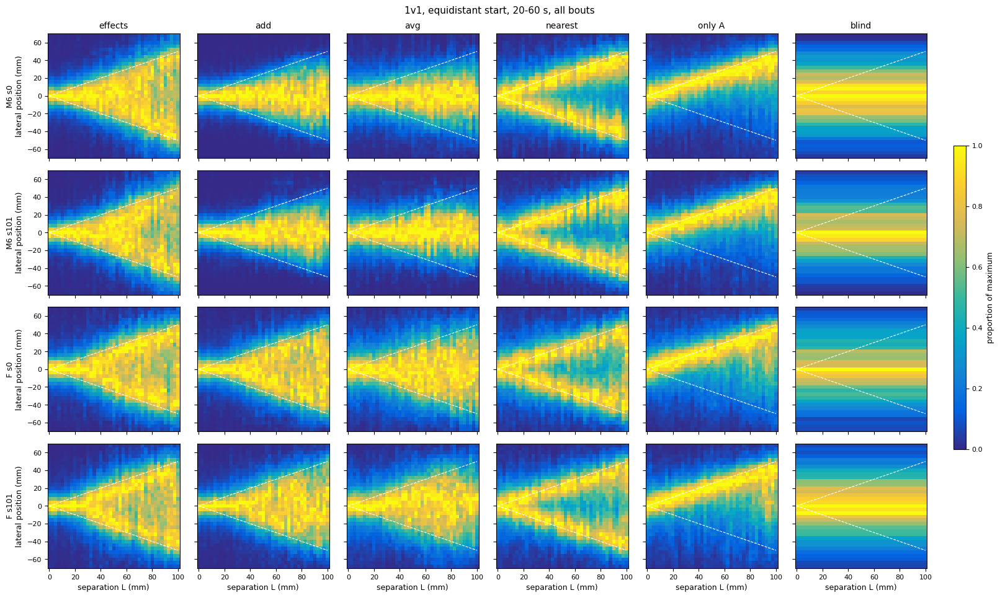

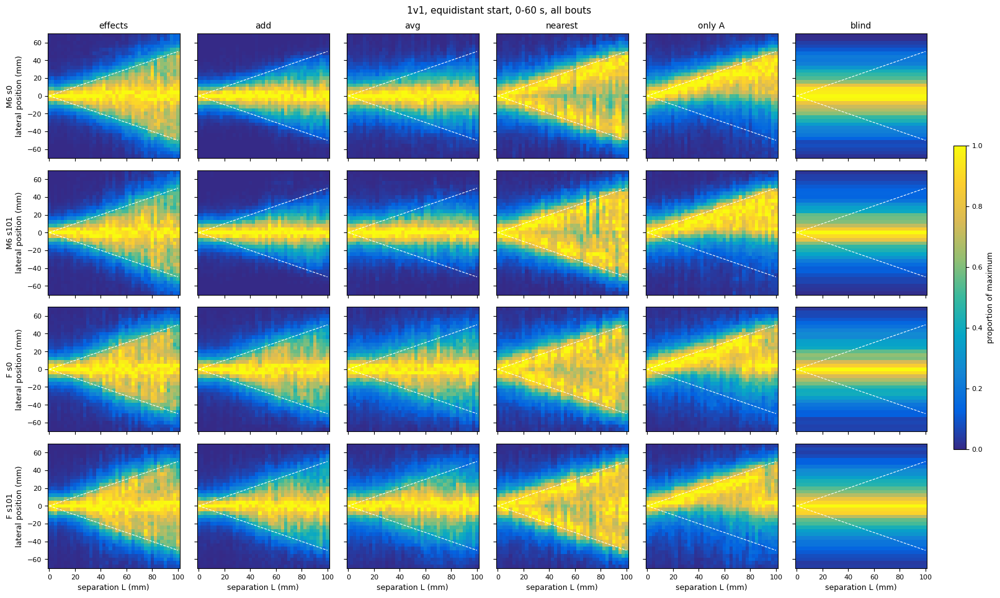

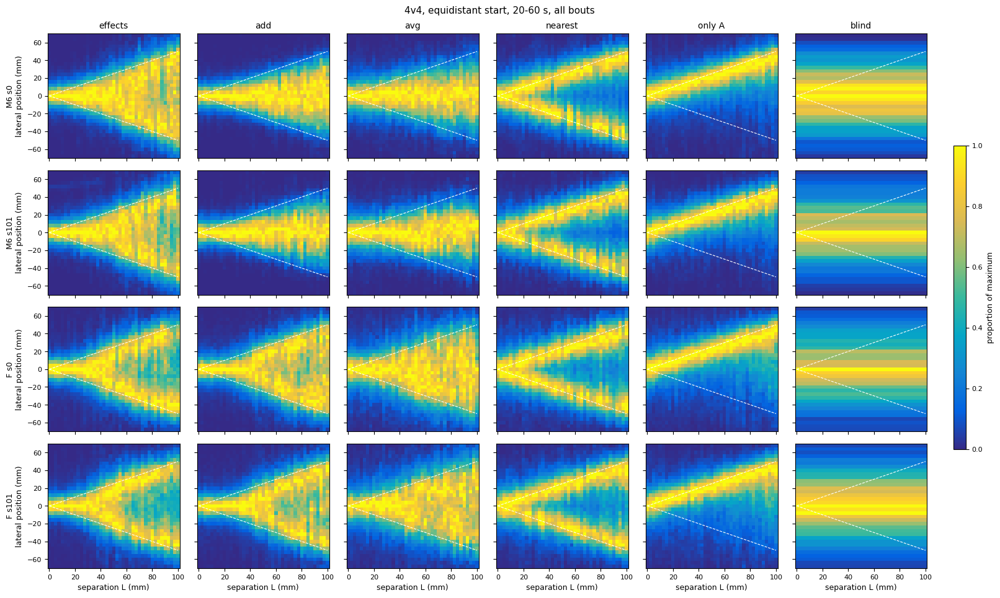

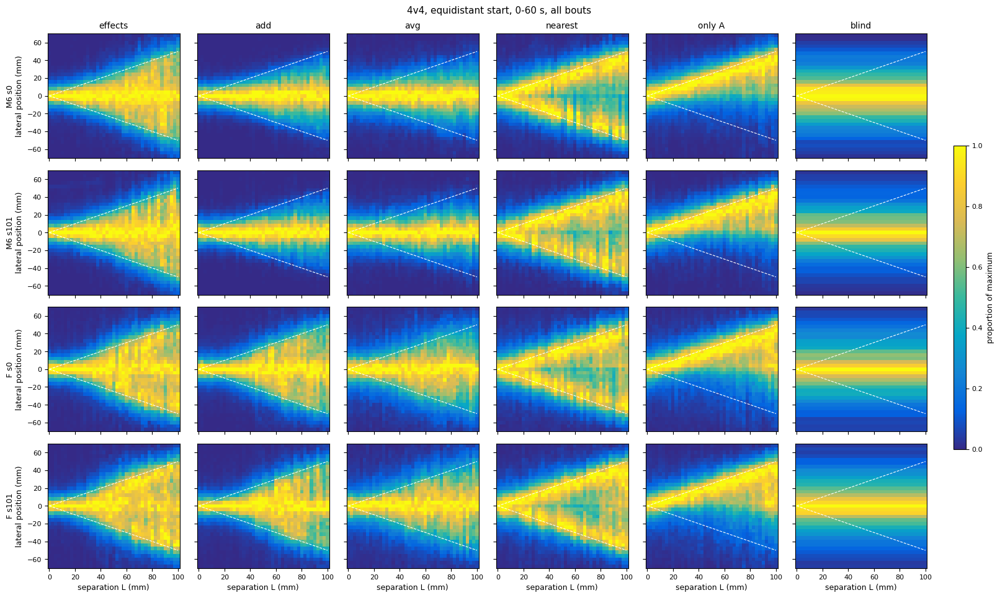

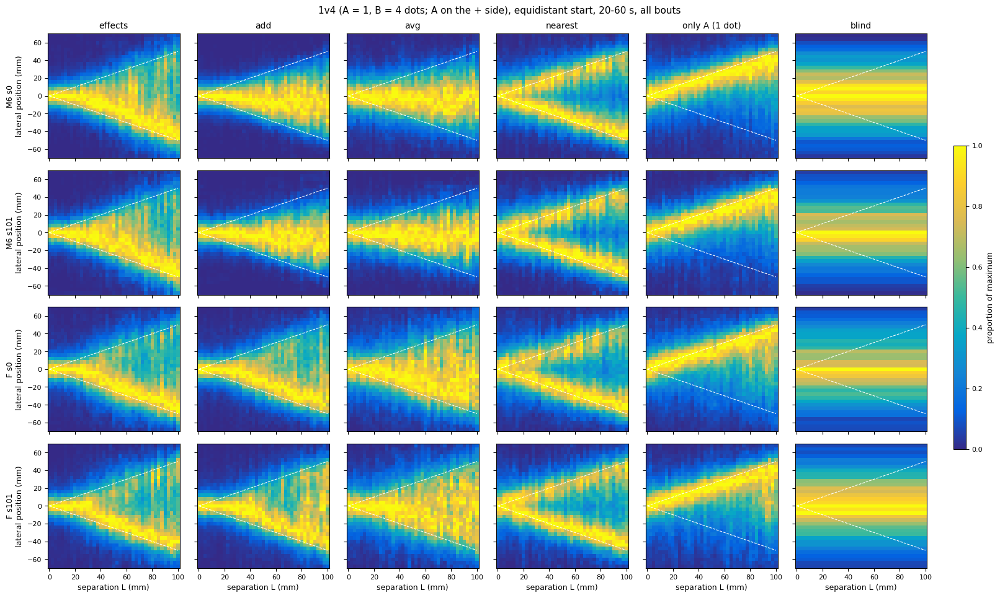

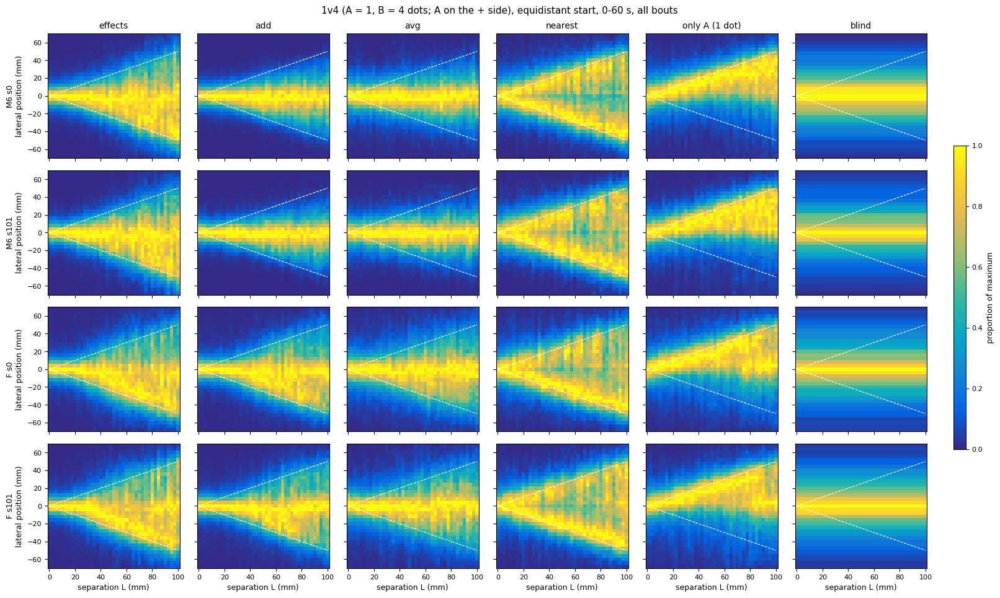

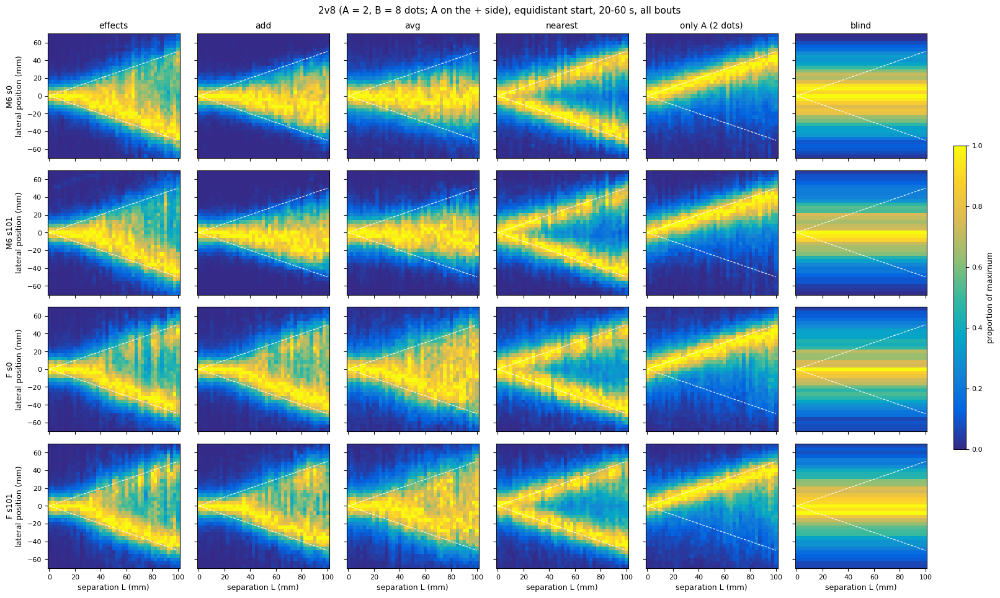

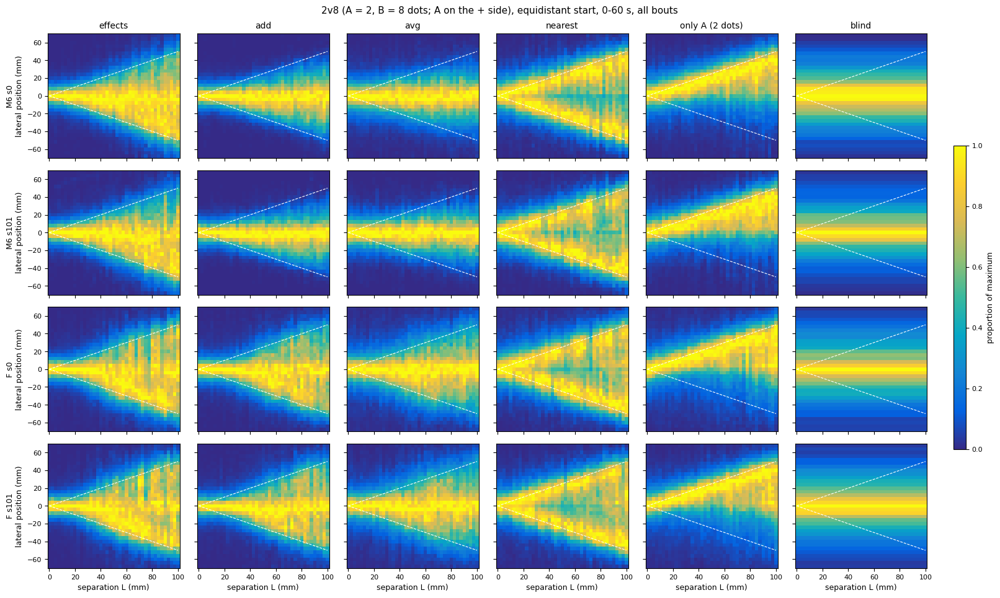

In [ ]:
for pair in TT.REPORT_PAIRS:
    for t_min in (20, 0):
        report_map(pair, t_min, select="all")

<a id="report-maps-behind"></a>
### 9c. The same maps with the paper's rule: bouts behind the pair

As section 9, but each column counts the bouts where the fish is **behind the pair**: its position, measured from the
midpoint between the two group centroids along the direction the pair is moving, is at or behind that midpoint. This is
the only selection Sridhar et al. (2021) state ('only data where the real fish swims behind the virtual fish'): no
lateral cut and no limit on how far behind (section 9 adds both, the L/2 + 15 mm cut and 40 mm behind; 9b drops both).
It removes mainly the bouts just after each U-turn, when the fish is ahead of the pair and turning back. Saved as
`report_map_<pair>_<window>_behind.pdf`.

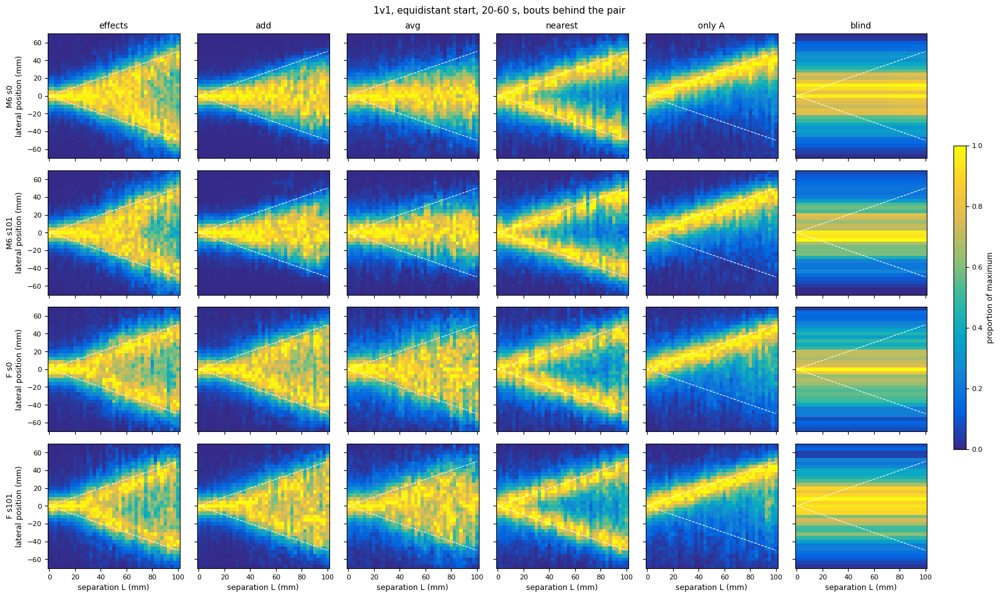

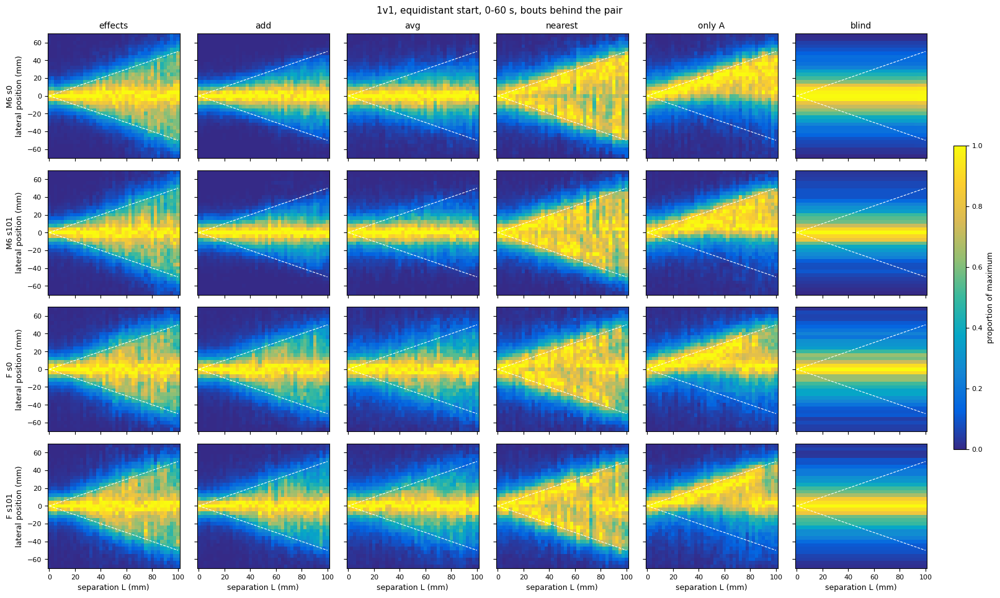

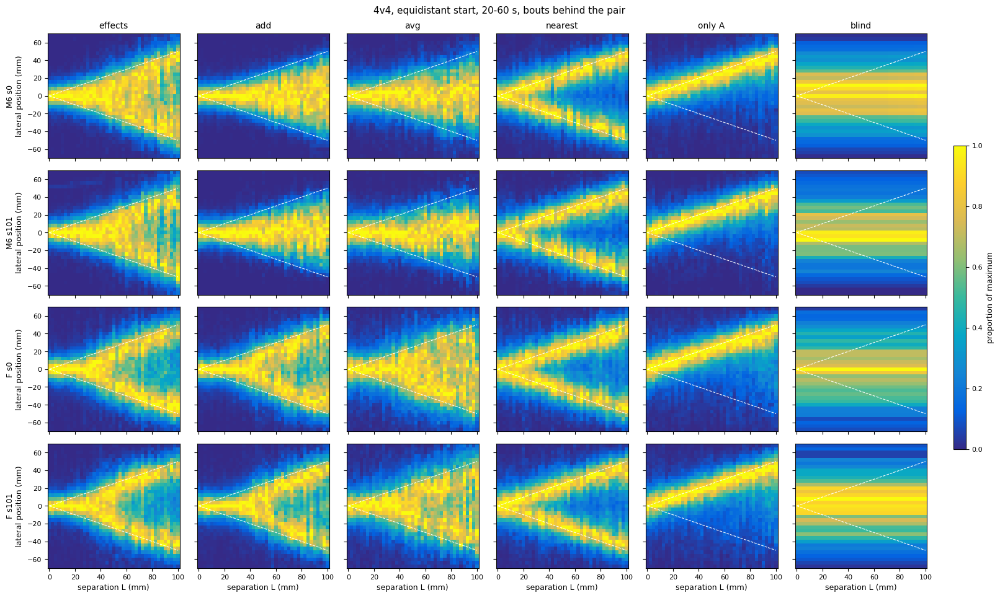

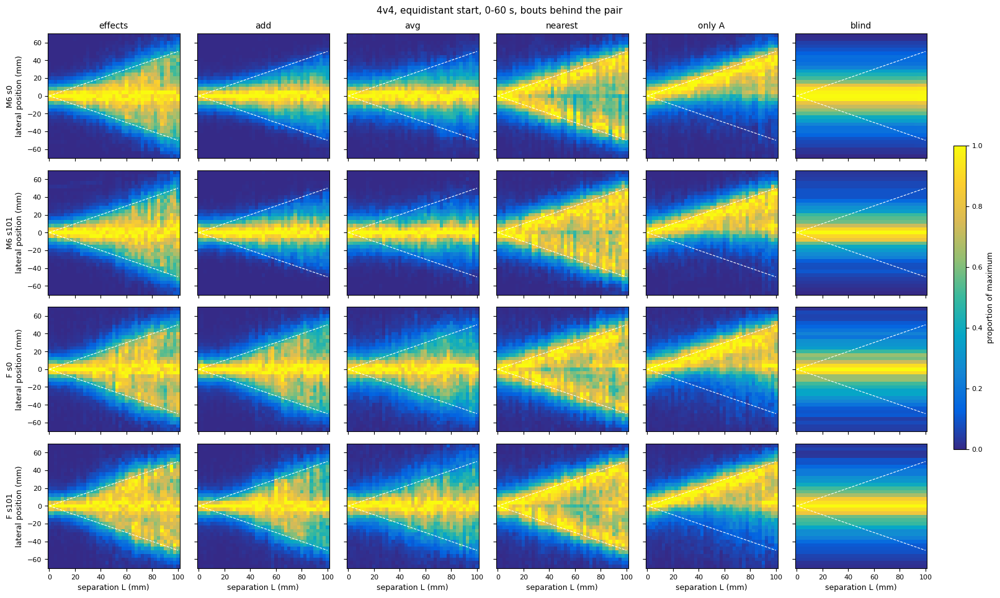

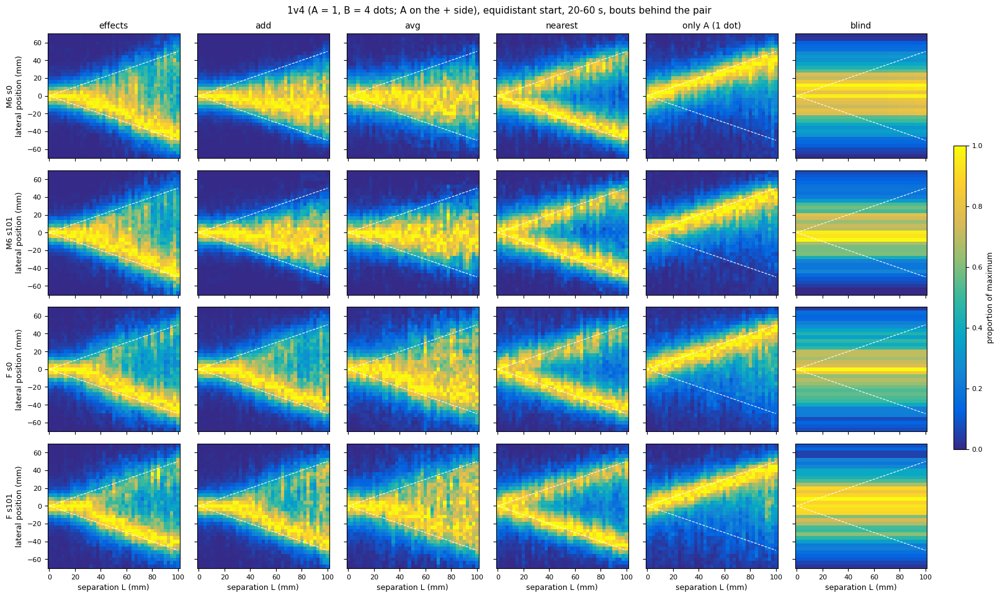

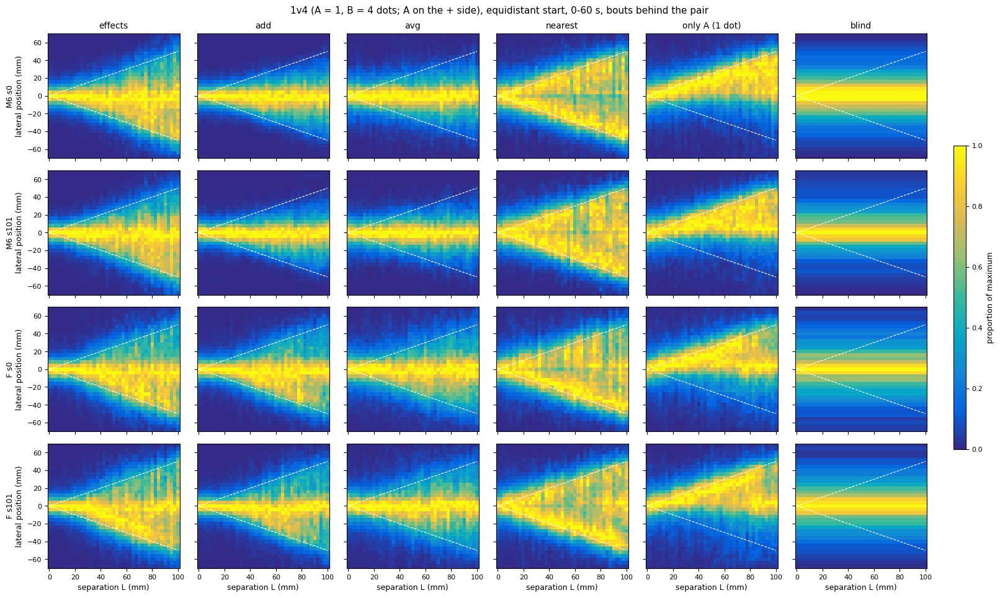

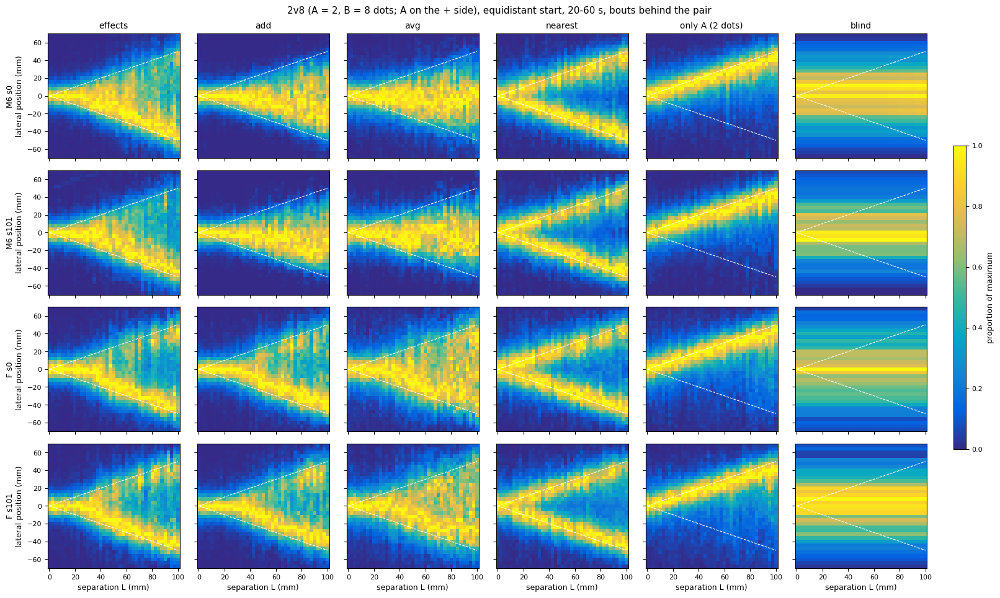

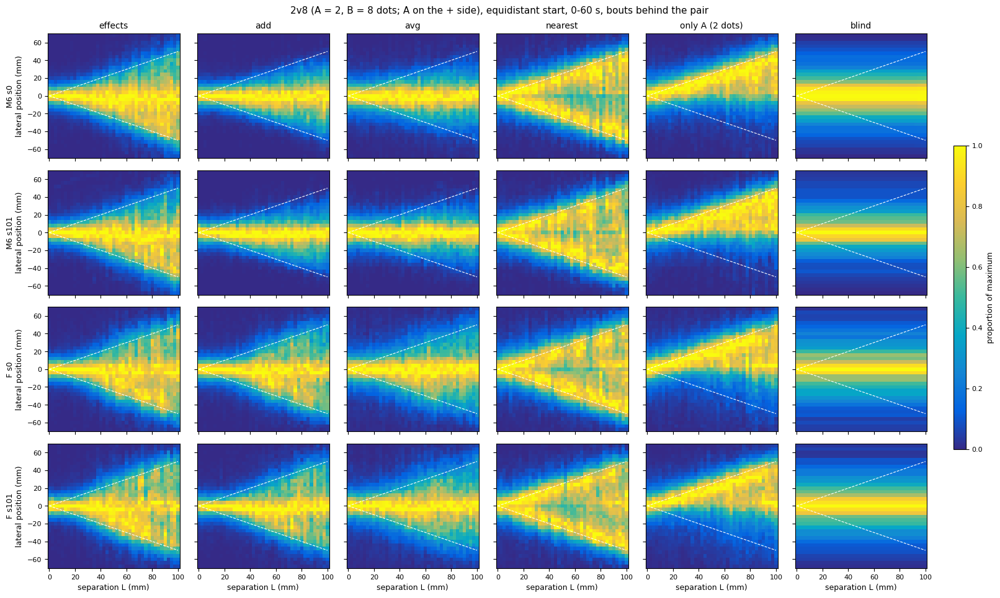

In [ ]:
for pair in TT.REPORT_PAIRS:
    for t_min in (20, 0):
        report_map(pair, t_min, select="behind")